# TV5 — CNN một bước và thực nghiệm so sánh

        ## 1. Tiếp nhận source và kiểm thử baseline

        Nhận model, exports và bảy tests từ PR #9, commit edc2bd953c7644040f4142a545316377cd143e13. Mục này xác minh source trong workspace, unit tests và hình dạng đầu ra. Dữ liệu dùng trong cell kiểm model là tensor tổng hợp.

        Mục 1 đã nhận nguyên source float32 và baseline 7 tests, xem receipt lịch sử. Từ mục 2, CNN dùng CPU float64, một feature và một output. Số tham số vẫn là 17.057.

        **Quyết định phương án A ngày 26/11/2026.** Giữ một cấu hình CNN hiện có để so với LSTM, ba seed 42/123/456, tối đa 100 epoch/run, patience 10, trần 300 epoch.

        ## 2. Kiến trúc và contract

        Chọn float64 để giữ cùng precision với LSTM theo yêu cầu hoàn thành mục 2, không đổi torch global dtype. Model nhận tensor hữu hạn trên CPU (B,30,1) và trả (B,1). Khóa một feature, một output; kiểm config sai kiểu/số không hợp lệ và finite input/output. Giữ Conv 1→16→32, kernel3, pool2, dropout0,1, Linear480→32→1. Dữ liệu thật, Adam/reload và thực nghiệm AAPL sẽ kiểm theo các mục sau.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, subprocess
from datetime import datetime, timezone
import xml.etree.ElementTree as ET
import pandas as pd
import torch
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'rule.md').is_file() and (p / 'backend/models/cnn_one_step/model.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from backend.models.cnn_one_step import CNNOneStep
pointer = json.loads((ROOT / 'logs/audit/tv5_item1_latest.json').read_text(encoding='utf-8'))
intake = json.loads((ROOT / pointer['intake']).read_text(encoding='utf-8'))
display(pd.DataFrame(intake['files']))
print('Commit', intake['commit'])
baseline = json.loads((ROOT / pointer['tests']).read_text(encoding='utf-8'))
print('Baseline mục 1 đã lưu', baseline['tests'], 'tests, dtype', baseline['dtype'])
print('Python', sys.executable)
print('PyTorch', torch.__version__)
assert sys.prefix != sys.base_prefix
assert Path(torch.__file__).resolve().is_relative_to(Path(sys.prefix).resolve())

,path,sha256
0,backend/models/cnn_one_step/model.py,5c465f8929898cbae810bbf49cfdd9a9df80b4af7c548b...
1,backend/models/cnn_one_step/__init__.py,d6cabad94b4fc8ee346bd28180e0d9ce73bf582689eff8...
2,tests/models/test_cnn_one_step.py,66542bce23369b83b9f2ec3cb0c71f583a79a55ad4ea54...


Commit edc2bd953c7644040f4142a545316377cd143e13
Baseline mục 1 đã lưu 7 tests, dtype torch.float32
Python D:\learn_DeepLearning\Project_course-work\.venv\tv4_clean\Scripts\python.exe
PyTorch 2.14.1+cpu


In [2]:
folder = ROOT / 'logs/audit' / ('tv5_tests_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
folder.mkdir(parents=True)
env = dict(os.environ, OMP_NUM_THREADS='1', MKL_NUM_THREADS='1', PYTHONIOENCODING='utf-8')
env.pop('PYTHONPATH', None)
command = [sys.executable, '-X', 'utf8', '-m', 'pytest', 'tests/models/test_cnn_one_step.py', 'tests/models/test_cnn_contract.py',
           '-q', '-p', 'no:cacheprovider', '--junitxml=' + str(folder / 'junit.xml')]
run = subprocess.run(command, cwd=ROOT, env=env, capture_output=True, text=True, encoding='utf-8')
(folder / 'pytest.log').write_text(run.stdout + run.stderr, encoding='utf-8')
print(run.stdout)
if run.returncode:
    raise RuntimeError(run.stderr or run.stdout)
cases = list(ET.parse(folder / 'junit.xml').getroot().iter('testcase'))
assert len(cases) == 26
assert all(c.find('failure') is None and c.find('error') is None and c.find('skipped') is None for c in cases)
display(pd.DataFrame([{'test': c.get('name'), 'seconds': c.get('time'), 'result': 'PASS'} for c in cases]))

..........................                                               [100%]
26 passed in 5.59s



,test,seconds,result
0,test_forward_shape,0.067,PASS
1,test_rejects_wrong_input_shape,0.002,PASS
2,test_deterministic_in_eval_with_seed,0.020,PASS
3,test_samples_are_independent,0.006,PASS
4,test_gradients_flow,0.029,PASS
5,test_config_roundtrip_and_param_count,0.002,PASS
6,test_invalid_config,0.001,PASS
7,test_invalid_contract_config[lookback-10],0.001,PASS
8,test_invalid_contract_config[n_features-2],0.001,PASS
9,test_invalid_contract_config[output_size-5],0.001,PASS


In [3]:
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    model = CNNOneStep().eval()
    x = torch.zeros(2, 30, 1, dtype=torch.float64)
    with torch.inference_mode():
        prediction = model(x)
assert prediction.shape == (2, 1) and torch.isfinite(prediction).all()
assert Path(sys.modules[CNNOneStep.__module__].__file__).resolve().is_relative_to(ROOT / 'backend')
print(model)
display(pd.DataFrame([{'input_shape': tuple(x.shape), 'output_shape': tuple(prediction.shape),
                       'dtype': str(prediction.dtype), 'parameters': model.count_parameters(),
                       'data': 'Tensor tổng hợp'}]))

CNNOneStep(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.1, inplace=False)
    (2): Linear(in_features=480, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


,input_shape,output_shape,dtype,parameters,data
0,"(2, 30, 1)","(2, 1)",torch.float64,17057,Tensor tổng hợp


In [4]:
changed = [name for name, expected in intake['protected_hashes'].items()
           if hashlib.sha256((ROOT / name).read_bytes()).hexdigest() != expected]
allowed5_path = ROOT / 'reports/audits/TV5_Item5_Source_Changes.json'
allowed5 = json.loads(allowed5_path.read_text(encoding='utf-8')) if allowed5_path.is_file() else {}
allowed6_path = ROOT / 'reports/audits/TV5_Item6_Source_Changes.json'
if allowed6_path.is_file():
    allowed5.update(json.loads(allowed6_path.read_text(encoding='utf-8')))
unexpected = [name for name in changed if allowed5.get(name) != hashlib.sha256((ROOT / name).read_bytes()).hexdigest()]
assert not unexpected, unexpected
intentional = [row['path'] for row in intake['files']
               if hashlib.sha256((ROOT / row['path']).read_bytes()).hexdigest() != row['sha256']]
assert set(intentional) == {'backend/models/cnn_one_step/model.py', 'tests/models/test_cnn_one_step.py'}
receipt = dict(passed=True, tests=len(cases), commit=intake['commit'], scope='TV5 item2 contract', source_unchanged=False, intentional_source_changes=intentional,
               protected_changes=changed, executable=sys.executable, torch=torch.__version__,
               parameters=model.count_parameters(), dtype=str(prediction.dtype))
(folder / 'summary.json').write_text(json.dumps(receipt, indent=2), encoding='utf-8')
pointer['item2_tests'] = (folder / 'summary.json').relative_to(ROOT).as_posix()
(ROOT / 'logs/audit/tv5_item1_latest.json').write_text(json.dumps(pointer, indent=2), encoding='utf-8')
display(pd.DataFrame([receipt]))
print('Bằng chứng', folder / 'summary.json')
display(Markdown('**Mục 2 đã kiểm chứng contract và CPU float64. Tiếp theo là mục 3, nối dữ liệu TV2 cho CNN.**'))

,passed,tests,commit,scope,source_unchanged,intentional_source_changes,protected_changes,executable,torch,parameters,dtype
0,True,26,edc2bd953c7644040f4142a545316377cd143e13,TV5 item2 contract,False,"[backend/models/cnn_one_step/model.py, tests/m...",[backend/experiments/runner/experiment_runner.py],D:\learn_DeepLearning\Project_course-work\.ven...,2.14.1+cpu,17057,torch.float64


Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_tests_20261126T041548378843Z\summary.json


**Mục 2 đã kiểm chứng contract và CPU float64. Tiếp theo là mục 3, nối dữ liệu TV2 cho CNN.**

## 3. Dữ liệu TV2 cho CNN

        Consumer CNN dùng lại factory dữ liệu đã kiểm của TV4 và cấu hình lookback30/common60 đã train. Cùng 1.954 mẫu train, 250 validation, scaler và ngày target. Kiểm ID theo thứ tự, đối chiếu từng X/y với prepared artifact và forward toàn bộ batch bằng CNN khởi tạo. Transpose (B,30,1) thành (B,1,30) diễn ra bên trong model.

        Lượt kiểm này chỉ xác minh dữ liệu/forward. Model dùng trọng số khởi tạo, không tính metric chất lượng dự báo.

In [5]:
data_check = subprocess.run([sys.executable, '-X', 'utf8', str(ROOT / 'scripts/check_tv5_aapl_data.py')],
                            cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
if data_check.returncode:
    raise RuntimeError(data_check.stderr or data_check.stdout)
path3 = Path(json.loads(data_check.stdout)['evidence'])
item3 = json.loads(path3.read_text(encoding='utf-8'))
assert item3['passed'] and not item3['trained']
display(pd.DataFrame([{key:value for key,value in row.items() if key != 'example'} for row in item3['results']]))
display(pd.DataFrame([dict(split=row['split'], **row['example']) for row in item3['results']]))
display(item3['provenance'])
print('Bằng chứng', path3)
display(Markdown('**Mục 3 kiểm dữ liệu và forward đã đạt. Tiếp theo là mục 4, nghiệm thu sâu model/gradient/dropout/lưu-nạp.**'))

,split,samples,batches,final_batch,first_origin,first_target,last_target,ordered_ids_sha256,input_shape,target_shape
0,train,1954,62,2,2015-03-30,2015-03-31,2022-12-30,f54f5c66f2c00e01a73c3d75ae2c4a534c5a4c41e99178...,"[1954, 30, 1]","[1954, 1]"
1,val,250,8,26,2022-12-30,2023-01-03,2023-12-29,f396ebb9da19ba432de552b77c76daf6f15487f953a92c...,"[250, 30, 1]","[250, 1]"


,split,sample_id,origin,target_date,last_five_scaled,target_scaled
0,train,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2015-03-30,2015-03-31,"[-0.8642024448382272, -0.8793122402750052, -0....",-0.874519
1,val,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2022-12-30,2023-01-03,"[1.221733110941285, 1.1847574036494766, 1.1041...",1.084539


{'dataset_version': 'aapl_2015_2025_acq_20261119T141302002415Z',
 'source_hashes': {'raw': 'cbcadbc002d05bc27a573114b9bb73b930733585b7823d147ca3477354479351',
  'metadata': '71213959ec9c111a1826db9058dc41f61772af9a0324a4e32ff61eb3bf0edc24',
  'validated': 'ee56f9c782ac9e938985c680a9015d1ae198982e7d1cddc49ee5d67630c7b16d',
  'validation_report': '4c28421c1488cfa3451fbd9661eed9fc4874a9295389e9221ed100fd10c2aa85',
  'quality_audit': 'f78e41b5006679a32aa97e454d3597ec0847979bcc727ce858a60d73d203e52d'},
 'scaler_id': 'aapl_scaler_20261120T124720810874Z',
 'prepared_id': 'tv4_lb30_20261125T120957429763Z',
 'scaler_path': 'artifacts/scalers/aapl_scaler_20261120T124720810874Z',
 'scaler_manifest_sha256': '695905a39615e336f83de1ab781f4f893e599e59a5e2685d1e77e4881174b4f5',
 'prepared_manifest_sha256': 'a5e946266bc385cecaec1deae6242a7216429b02cc259ffe5069221f066d4150'}

Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item3_20261126T041639714502Z\summary.json


**Mục 3 kiểm dữ liệu và forward đã đạt. Tiếp theo là mục 4, nghiệm thu sâu model/gradient/dropout/lưu-nạp.**

## 4. Nghiệm thu khả năng học và lưu/nạp CNN

        Kiểm tổng hợp với batch 1 và 32, gradient hữu hạn và khác 0 ở từng tensor tham số, Adam cập nhật trọng số, zero_grad xóa gradient. Kiểm dropout train/eval và output eval ổn định. Sau một Adam step tổng hợp, lưu config/state_dict ra file thật và nạp vào instance mới, yêu cầu output eval bằng chính xác. Từ chối state_dict thiếu key.

        Đây là diagnostic bằng tensors tổng hợp, chưa train AAPL hoặc đánh giá chất lượng. Checkpoint có provenance và tích hợp trainer tiếp tục ở mục 5/6.

In [6]:
import xml.etree.ElementTree as ET
folder4 = ROOT / 'logs/audit' / ('tv5_item4_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
folder4.mkdir(parents=True)
xml4 = folder4 / 'tests.xml'
command4 = [sys.executable, '-m', 'pytest', 'tests/models/test_cnn_one_step.py',
            'tests/models/test_cnn_contract.py', 'tests/models/test_cnn_learning.py',
            'tests/training', '-q', '-p', 'no:cacheprovider', '--junitxml=' + str(xml4)]
run4 = subprocess.run(command4, cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
(folder4 / 'pytest.txt').write_text(run4.stdout + run4.stderr, encoding='utf-8')
if run4.returncode:
    raise RuntimeError(run4.stdout + run4.stderr)
cases4 = list(ET.parse(xml4).getroot().iter('testcase'))
assert cases4 and all(not any(c.tag in ('failure','error','skipped') for c in case) for case in cases4)
rows4 = [{'test':case.attrib['name'], 'seconds':float(case.attrib['time'])} for case in cases4]
receipt4 = {'passed':True, 'tests':len(cases4), 'scope':'synthetic CNN diagnostics and training regression',
            'aapl_training':False, 'command':command4, 'python':sys.version, 'torch':torch.__version__}
(folder4 / 'summary.json').write_text(json.dumps(receipt4, indent=2), encoding='utf-8')
display(pd.DataFrame([receipt4]))
display(pd.DataFrame([r for r in rows4 if any(k in r['test'] for k in ('adam','dropout','roundtrip'))]))
print('Bằng chứng', folder4 / 'summary.json')
display(Markdown('**Mục 4 đạt kiểm chứng local. Tiếp theo mục 5, nối CNN vào training loop chung TV4.**'))

,passed,tests,scope,aapl_training,command,python,torch
0,True,138,synthetic CNN diagnostics and training regression,False,[D:\learn_DeepLearning\Project_course-work\.ve...,"3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:...",2.14.1+cpu


,test,seconds
0,test_config_roundtrip_and_param_count,0.009
1,test_invalid_contract_config[dropout-nan],0.002
2,test_invalid_contract_config[dropout-inf],0.002
3,test_invalid_contract_config[dropout-True],0.007
4,test_invalid_contract_config[dropout--0.1],0.039
5,test_invalid_contract_config[dropout-1.0],0.006
6,test_gradients_and_adam_update[1],8.852
7,test_gradients_and_adam_update[32],0.026
8,test_dropout_modes_and_eval_determinism,0.028
9,test_real_file_roundtrip_after_adam,0.093


Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item4_20261126T041640787129Z\summary.json


**Mục 4 đạt kiểm chứng local. Tiếp theo mục 5, nối CNN vào training loop chung TV4.**

## 5. Nối CNN vào training loop chung TV4

        YAML CNN dùng schema kiến trúc CNN và cùng data/scaler/common-history với LSTM đối ứng. Runner chọn factory CNN, còn train_model/_run_epoch vẫn là code TV4. Adam/MSE và early stopping dùng chung; không tạo vòng train riêng.

        Kiểm tổng hợp chạy CNN qua runner một epoch, validation không gradient và không đổi weights, weighted loss giữ batch cuối 1 mẫu, plateau có kiểm soát dừng sau patience và khôi phục best weights. Plateau là tín hiệu kiểm thử, không phải kết quả CNN trên AAPL. Kiểm nối loader thật ở dưới chỉ đọc dữ liệu. Chưa train AAPL hoặc lưu checkpoint CNN có provenance, các mục 6/7 tiếp tục phần đó.

In [7]:
from backend.experiments.runner.experiment_runner import load_experiment_config
from backend.experiments.runner.cnn_factories import make_cnn_model, make_cnn_loaders
config5 = load_experiment_config(str(ROOT / 'experiments/configs/cnn_one_step_baseline.yaml'))
assert config5['seeds'] == [42,123,456]
train5, val5 = make_cnn_loaders(config5, 42, project_root=ROOT)
assert len(train5.dataset) == 1954 and len(val5.dataset) == 250
assert make_cnn_model(config5).count_parameters() == 17057
runner_cases5 = [case for case in cases4 if 'test_cnn_runner' in case.attrib.get('classname','')]
assert len(runner_cases5) == 9
display(pd.DataFrame([{'test':c.attrib['name'], 'result':'PASS'} for c in runner_cases5]))
display(pd.DataFrame([{'split':name, 'samples':len(dl.dataset), 'batches':len(dl),
    'tail':len(dl.dataset) % dl.batch_size, 'drop_last':dl.drop_last}
    for name,dl in [('train',train5),('validation',val5)]]))
display(config5)
receipt5 = dict(passed=True, integration_tests=len(runner_cases5), regression_tests=len(cases4),
    aapl_training=False, checkpoint_mode='RAM only pending item6', tests_evidence=str(folder4 / 'summary.json'))
folder5 = ROOT / 'logs/audit' / ('tv5_item5_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
folder5.mkdir(parents=True)
(folder5 / 'summary.json').write_text(json.dumps(receipt5,indent=2),encoding='utf-8')
print('Bằng chứng',folder5 / 'summary.json')
display(Markdown('**Mục 5 đã nối loop chung và kiểm chứng local. Tiếp theo mục 6, checkpoint CNN và provenance.**'))

,test,result
0,test_invalid_cnn_experiment[data-forecast_leng...,PASS
1,test_invalid_cnn_experiment[data-lookback-60],PASS
2,test_invalid_cnn_experiment[data-common_histor...,PASS
3,test_invalid_cnn_experiment[model-output_size-5],PASS
4,test_invalid_cnn_experiment[training-optimizer...,PASS
5,test_cnn_validation_weighted_loss_no_grad_and_...,PASS
6,test_cnn_real_training_early_stop_restores_best,PASS
7,test_runner_selects_cnn_factory_and_ram_mode,PASS
8,test_config_reference_preserves_data_and_caller,PASS


,split,samples,batches,tail,drop_last
0,train,1954,62,2,False
1,validation,250,8,26,False


{'experiment_name': 'cnn_one_step_option_a',
 'model_type': 'cnn_one_step',
 'data': {'ticker': 'AAPL',
  'lookback': 30,
  'forecast_length': 1,
  'dataset_version': 'aapl_2015_2025_acq_20261119T141302002415Z',
  'scaler_id': 'aapl_scaler_20261120T124720810874Z',
  'prepared_id': 'tv4_lb30_20261125T120957429763Z',
  'scaler_manifest_sha256': '695905a39615e336f83de1ab781f4f893e599e59a5e2685d1e77e4881174b4f5',
  'prepared_manifest_sha256': 'a5e946266bc385cecaec1deae6242a7216429b02cc259ffe5069221f066d4150',
  'common_history': True},
 'model': {'lookback': 30,
  'n_features': 1,
  'conv1_channels': 16,
  'conv2_channels': 32,
  'kernel_size': 3,
  'pool_size': 2,
  'hidden_units': 32,
  'dropout': 0.1,
  'output_size': 1},
 'training': {'batch_size': 32,
  'optimizer': 'adam',
  'learning_rate': 0.001,
  'loss_function': 'mse',
  'max_epochs': 100,
  'early_stopping': {'patience': 10, 'monitor': 'val_loss', 'mode': 'min'}},
 'seeds': [42, 123, 456],
 'output': {'checkpoint_dir': 'artifac

Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item5_20261126T041829936658Z\summary.json


**Mục 5 đã nối loop chung và kiểm chứng local. Tiếp theo mục 6, checkpoint CNN và provenance.**

## Audit lại mục 1–5

        Audit source/config, hash bảo vệ, notebook, bộ tests đầy đủ và forward AAPL. Không train AAPL hoặc đánh giá test. Validator cấu hình chung chưa khóa ngân sách/kiến trúc phương án A; cần khóa và ghi fingerprint trước thực nghiệm chính thức. Script đối chiếu dữ liệu còn cần log TV4 local, cần đóng gói bằng chứng khi bàn giao mục 10. Xem reports/audits/TV5_Items1_5_Audit.md.

In [8]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
audit_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'rule.md').is_file())
audit_path = sorted((audit_root / 'logs/audit').glob('tv5_audit_1_5_*/summary.json'))[-1]
audit_result = json.loads(audit_path.read_text(encoding='utf-8'))
assert audit_result['passed'] and audit_result['tests'] == 111
display(pd.DataFrame([{key:audit_result[key] for key in ('passed','tests','aapl_training',
    'test_performance_evaluated','source_unchanged_during_audit','config_matches_lstm_data')}]))
display(pd.DataFrame(audit_result['generic_config_probes']))
display(pd.DataFrame(audit_result['data_results']).drop(columns=['example']))
print('Giới hạn audit', audit_result['limitations'])
print('Bằng chứng', audit_path)

,passed,tests,aapl_training,test_performance_evaluated,source_unchanged_during_audit,config_matches_lstm_data
0,True,111,False,False,True,True


,section,field,value,accepted_by_generic_validator
0,training,max_epochs,101,True
1,model,conv1_channels,32,True


,split,samples,batches,final_batch,first_origin,first_target,last_target,ordered_ids_sha256,input_shape,target_shape
0,train,1954,62,2,2015-03-30,2015-03-31,2022-12-30,f54f5c66f2c00e01a73c3d75ae2c4a534c5a4c41e99178...,"[1954, 30, 1]","[1954, 1]"
1,val,250,8,26,2022-12-30,2023-01-03,2023-12-29,f396ebb9da19ba432de552b77c76daf6f15487f953a92c...,"[250, 30, 1]","[250, 1]"


Giới hạn audit ['Generic config validation does not lock Option A architecture/budget', 'Data audit requires local historical TV4 evidence', 'No AAPL training or final checkpoint acceptance in items 1-5']
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_audit_1_5_20261126T040833735453Z\summary.json


## 6. Checkpoint CNN và provenance

        Lưu weights.pt cùng manifest chứa kiến trúc, CPU float64, dataset/scaler/prepared IDs và hashes, run/seed, training config/fingerprint, source hashes, best validation epoch/loss và purpose. Bản diagnostic bị từ chối mặc định, kể cả đã chạy train tổng hợp. Loader yêu cầu expected provenance/config fingerprint, kiểm checksum và strict state_dict.

        Tests dùng identities và tensors tổng hợp, gồm runner hai epoch lưu best rồi nạp instance mới để đối chiếu MSE. Chưa train AAPL. Artifact này phục vụ nạp best model/inference, chưa chứa Adam state để resume training. Metadata là thông tin caller cung cấp, không tự chứng minh lịch sử train.

In [9]:
checkpoint_cases6 = [case for case in cases4 if 'test_cnn_checkpoint' in case.attrib.get('classname','')]
assert checkpoint_cases6
display(pd.DataFrame([{'test':c.attrib['name'],'result':'PASS'} for c in checkpoint_cases6]))
folder6 = ROOT / 'logs/audit' / ('tv5_item6_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
folder6.mkdir(parents=True)
receipt6 = dict(passed=True,checkpoint_tests=len(checkpoint_cases6),regression_tests=len(cases4),
    tests_evidence=str(folder4 / 'summary.json'),aapl_training=False,
    checkpoint_scope='Synthetic persistence/runner diagnostics, not AAPL trained model',
    supports_optimizer_resume=False)
(folder6 / 'summary.json').write_text(json.dumps(receipt6,indent=2),encoding='utf-8')
display(pd.DataFrame([receipt6]))
print('Bằng chứng',folder6 / 'summary.json')
display(Markdown('**Mục 6 kiểm chứng persistence local. Tiếp theo mục 7, smoke train/validation AAPL có giới hạn và purpose diagnostic.**'))

,test,result
0,test_diagnostic_reload_exact_and_immutable,PASS
1,test_reject_mismatched_provenance[dataset_vers...,PASS
2,test_reject_mismatched_provenance[scaler_id],PASS
3,test_reject_mismatched_provenance[prepared_id],PASS
4,test_reject_mismatched_provenance[source_hashes],PASS
5,test_reject_mismatched_provenance[scaler_manif...,PASS
6,test_reject_mismatched_provenance[prepared_man...,PASS
7,test_reject_wrong_config_run_seed[expected_run...,PASS
8,test_reject_wrong_config_run_seed[expected_see...,PASS
9,test_reject_wrong_config_run_seed[expected_tra...,PASS


,passed,checkpoint_tests,regression_tests,tests_evidence,aapl_training,checkpoint_scope,supports_optimizer_resume
0,True,27,138,D:\learn_DeepLearning\Project_course-work\logs...,False,"Synthetic persistence/runner diagnostics, not ...",False


Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item6_20261126T041829981011Z\summary.json


**Mục 6 kiểm chứng persistence local. Tiếp theo mục 7, smoke train/validation AAPL có giới hạn và purpose diagnostic.**

## Sơ đồ tổng hợp các đường xử lý mục 1–6

        Bốn sơ đồ dưới đây diễn giải source đang triển khai, không phải kết quả train hoặc metric dự báo. Xem lần lượt luồng dữ liệu, các shape bên trong CNN, train/validation/chọn best và checkpoint save/load.

        Loss epoch được tính theo số mẫu, giữ batch cuối. Patience tăng khi validation không cải thiện và được reset khi có best mới. Checkpoint chỉ nạp khi các kiểm tra đều đạt; diagnostic bị từ chối mặc định. Expected identity/config phải đến từ handoff tin cậy. Hash phát hiện hỏng dữ liệu, không xác thực người gửi.

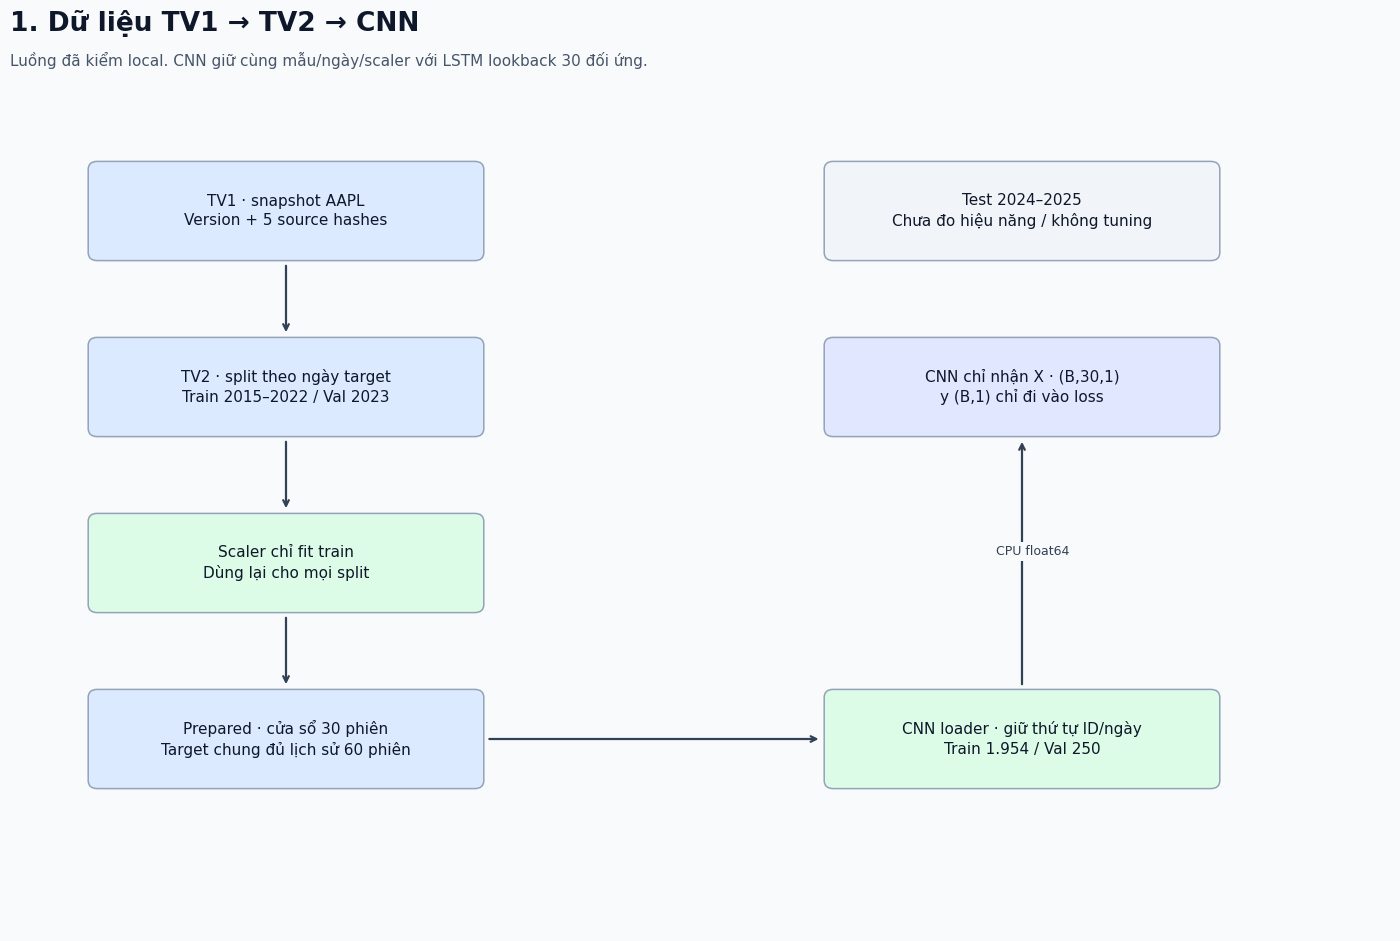

Ảnh đã lưu D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_diagrams_20261126T042128106254Z\01_data_flow.png


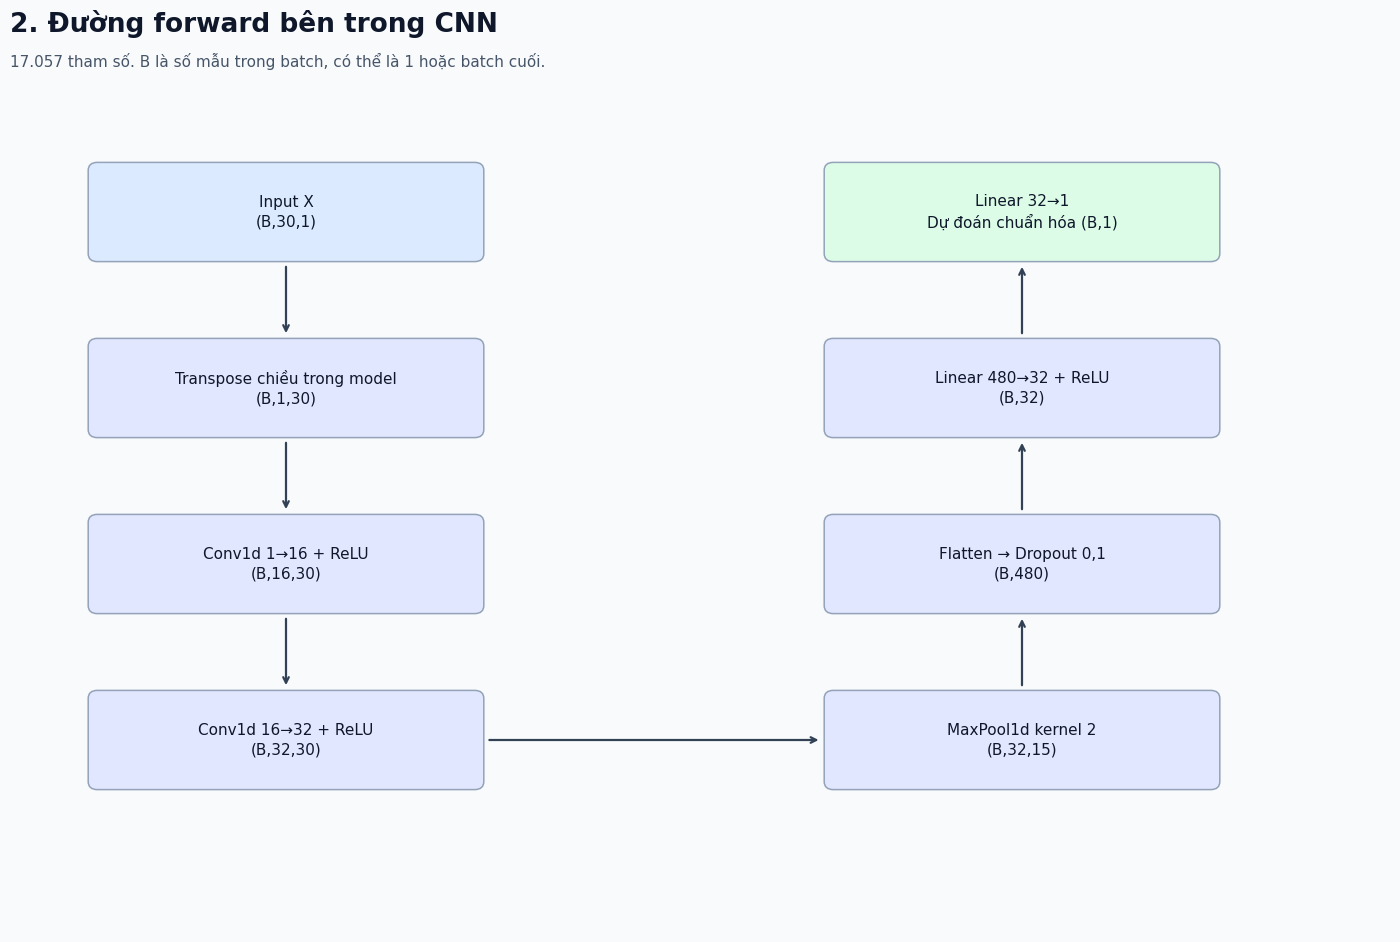

Ảnh đã lưu D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_diagrams_20261126T042128106254Z\02_cnn_shapes.png


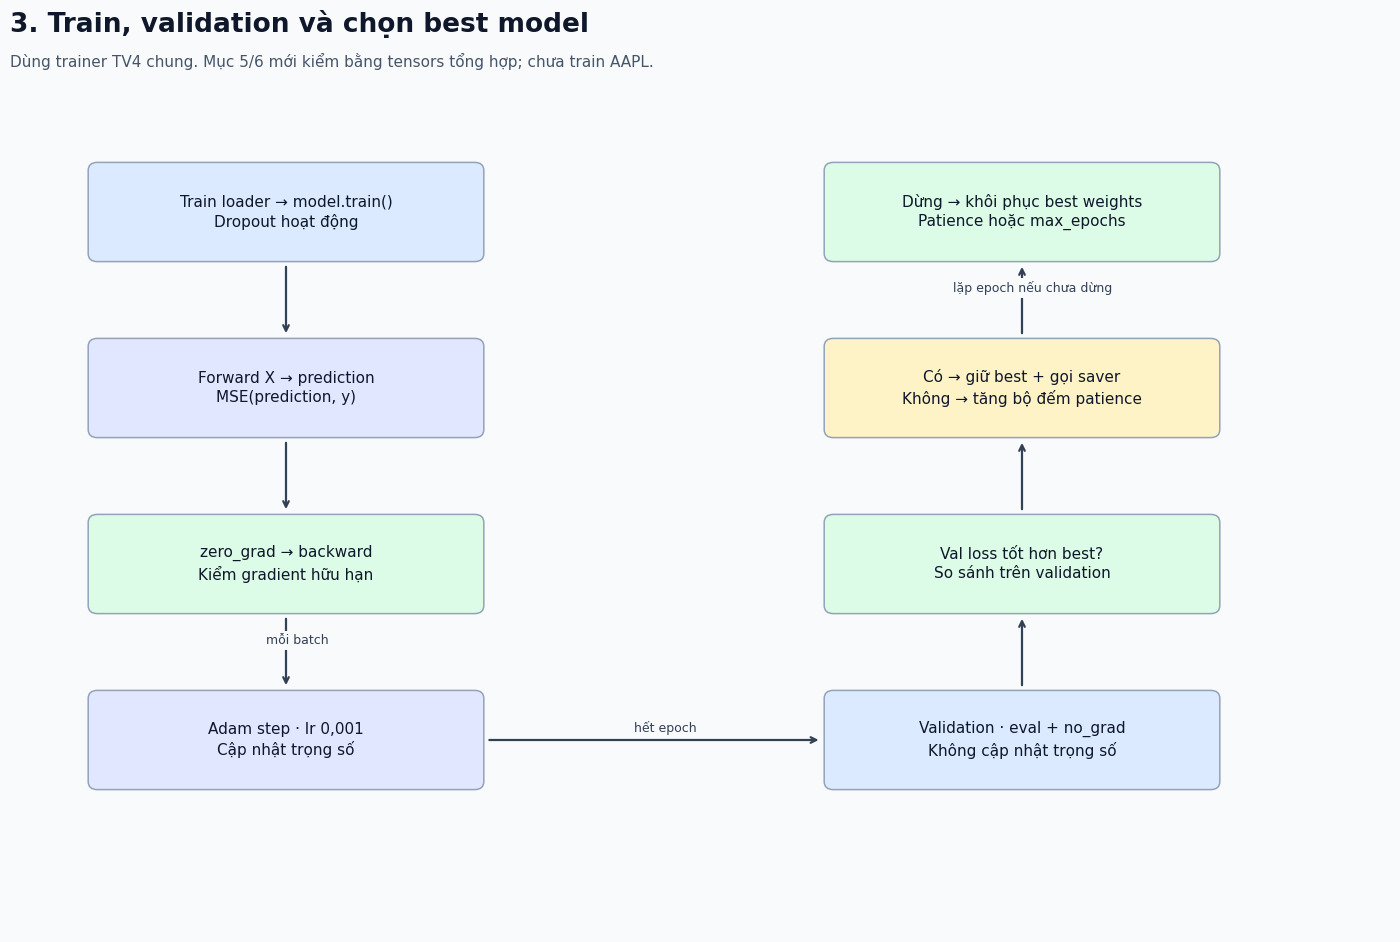

Ảnh đã lưu D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_diagrams_20261126T042128106254Z\03_training_selection.png


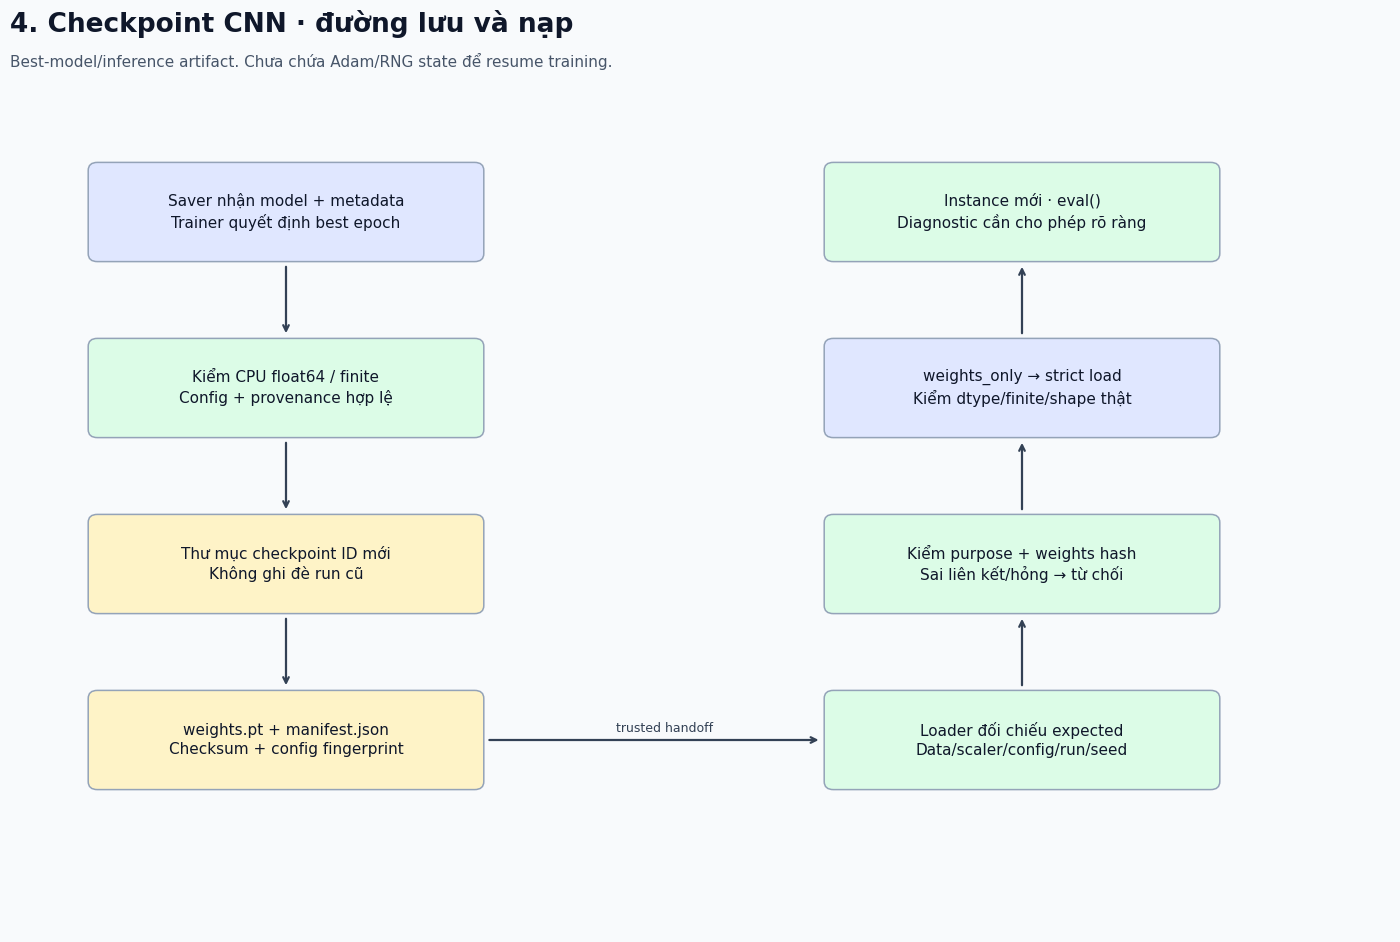

Ảnh đã lưu D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_diagrams_20261126T042128106254Z\04_checkpoint.png


In [1]:
from pathlib import Path
import sys
from datetime import datetime, timezone
from IPython.display import display
import matplotlib.pyplot as plt
diagram_root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / 'rule.md').is_file())
if str(diagram_root / 'scripts') not in sys.path:
    sys.path.insert(0,str(diagram_root / 'scripts'))
from tv5_notebook_diagrams import render_tv5_diagrams
diagram_folder = diagram_root / 'logs/audit' / ('tv5_diagrams_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
diagrams = render_tv5_diagrams(diagram_folder)
for figure, path in diagrams:
    display(figure)
    plt.close(figure)
    print('Ảnh đã lưu',path)
assert len(diagrams) == 4 and all(path.is_file() for _,path in diagrams)

## 7. Smoke run CNN trên AAPL — 5 epoch, seed 42

        Dùng đủ 1.954 mẫu train và 250 validation với cùng dữ liệu/scaler/LSTM đối ứng. Giữ Adam 0,001, MSE, batch32, float64 và một CPU thread. Run diagnostic giới hạn 5 epoch, không đánh giá test hoặc chọn lại kiến trúc/ngân sách từ kết quả smoke. Patience10 chưa thể kích hoạt trong giới hạn 5 epoch, logic này đã kiểm tổng hợp ở mục 5.

        CLI tái lập `python scripts/run_tv5_smoke.py` tạo run mới. Cell dưới đọc run smoke mới nhất, hiển thị kết quả thật và biểu đồ. Reload best checkpoint vào instance mới phải khớp output và validation MSE. Biểu đồ giá chuẩn hóa chỉ kiểm hành vi forward, không chứng minh chất lượng dự báo hoặc vượt baseline.

,epoch,train_loss,val_loss,learning_rate,time_seconds,train_seconds,validation_seconds,val_mse_per_horizon
0,1,0.601709,0.420335,0.001,0.391183,0.374637,0.016544,[0.4203353400588051]
1,2,0.164466,0.054332,0.001,0.338589,0.327587,0.011000,[0.054332359126796244]
2,3,0.021513,0.069751,0.001,0.387644,0.374186,0.013458,[0.06975089006927274]
3,4,0.030540,0.150875,0.001,0.349364,0.339465,0.009899,[0.1508751245497261]
4,5,0.030825,0.105344,0.001,0.284278,0.274313,0.009965,[0.1053436507027219]


,epochs,seed,best_epoch,best_val_loss,reload_val_loss,parameters,dtype,device,weights_changed,finite_weights
0,5,42,2,0.054332,0.054332,17057,float64,cpu,True,True


,train_batches,validation_batches,train_samples,validation_samples,validation_grad_enabled,gradient_tensors,max_abs_gradient
0,310,40,9770,1250,False,2480,5.194841


,runner_wall_seconds,process_cpu_seconds,training_loop_seconds,torch_threads
0,7.023544,4.53125,1.816242,1


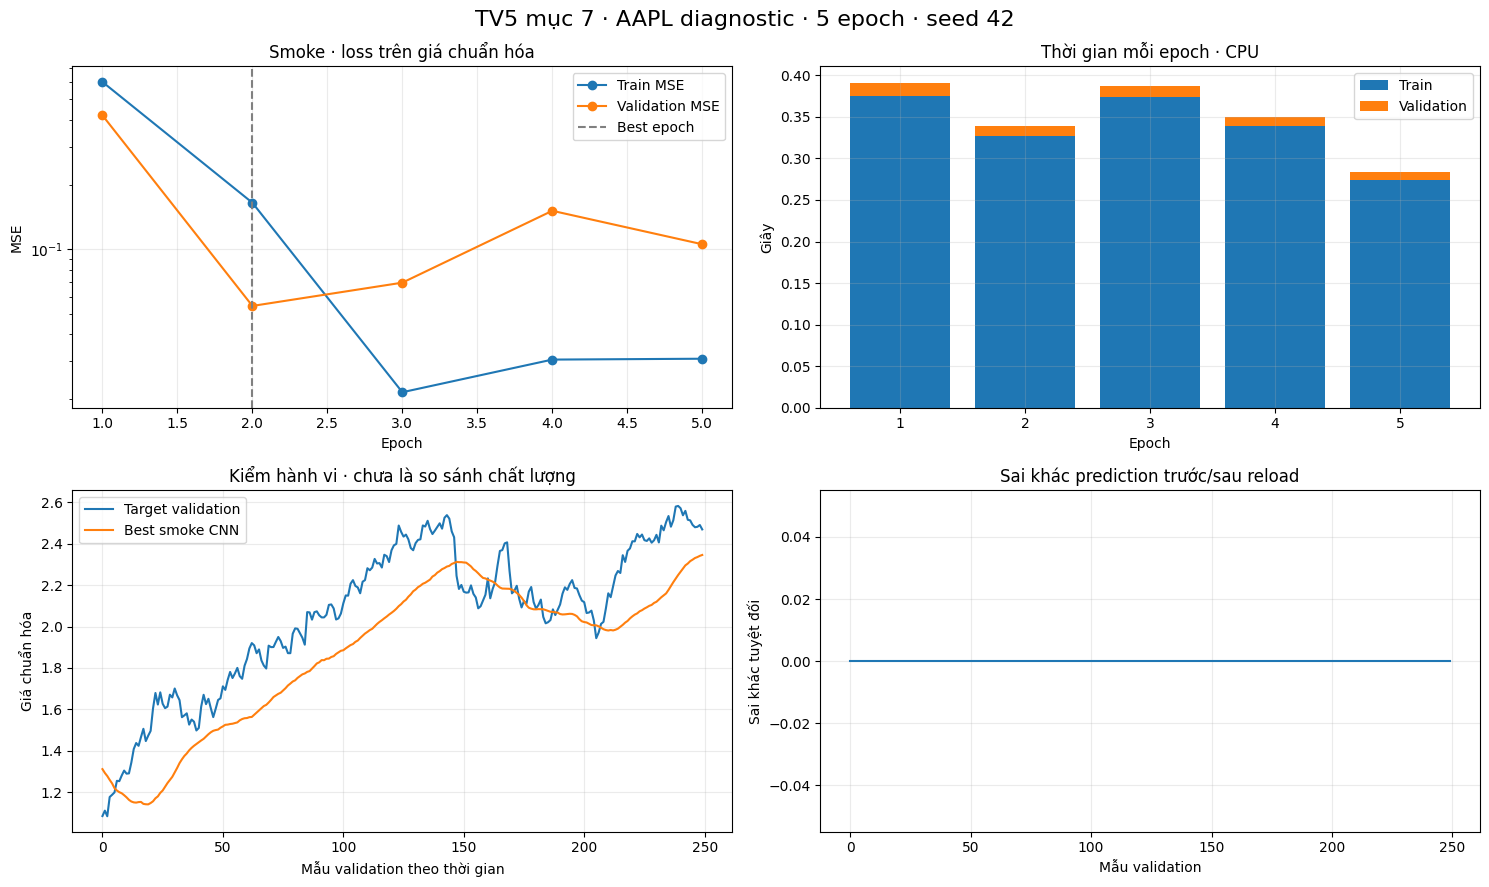

Checkpoint diagnostic logs/audit/tv5_item7_20261126T043358119493Z/checkpoints/cnn_one_step__cnn_aapl_smoke_diagnostic_5epochs__seed42__20261126_113434_679347__epoch2
Loader mặc định đã từ chối Diagnostic checkpoint is not a research model
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item7_20261126T043358119493Z\summary.json


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
smoke_root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / 'rule.md').is_file())
smoke_path = sorted((smoke_root / 'logs/audit').glob('tv5_item7_*/summary.json'))[-1]
smoke = json.loads(smoke_path.read_text(encoding='utf-8'))
assert smoke['passed'] and smoke['purpose'] == 'diagnostic' and smoke['aapl_training']
assert not smoke['test_performance_evaluated'] and smoke['reload_predictions_exact']
history7 = pd.read_csv(smoke_path.parent / 'history.csv')
predictions7 = pd.read_csv(smoke_path.parent / 'validation_scaled.csv')
display(history7)
display(pd.DataFrame([{key:smoke[key] for key in ('epochs','seed','best_epoch','best_val_loss',
    'reload_val_loss','parameters','dtype','device','weights_changed','finite_weights')}]))
display(pd.DataFrame([smoke['gradient_stats']]))
display(pd.DataFrame([smoke['timing']]))
fig,axes = plt.subplots(2,2,figsize=(15,9))
axes[0,0].plot(history7.epoch,history7.train_loss,'o-',label='Train MSE')
axes[0,0].plot(history7.epoch,history7.val_loss,'o-',label='Validation MSE')
axes[0,0].axvline(smoke['best_epoch'],linestyle='--',color='gray',label='Best epoch')
axes[0,0].set(title='Smoke · loss trên giá chuẩn hóa',xlabel='Epoch',ylabel='MSE',yscale='log')
axes[0,0].legend()
axes[0,1].bar(history7.epoch,history7.train_seconds,label='Train')
axes[0,1].bar(history7.epoch,history7.validation_seconds,bottom=history7.train_seconds,label='Validation')
axes[0,1].set(title='Thời gian mỗi epoch · CPU',xlabel='Epoch',ylabel='Giây')
axes[0,1].legend()
axes[1,0].plot(predictions7.target_scaled,label='Target validation',linewidth=1.5)
axes[1,0].plot(predictions7.prediction_scaled,label='Best smoke CNN',linewidth=1.5)
axes[1,0].set(title='Kiểm hành vi · chưa là so sánh chất lượng',xlabel='Mẫu validation theo thời gian',ylabel='Giá chuẩn hóa')
axes[1,0].legend()
axes[1,1].plot(predictions7.reload_abs_diff)
axes[1,1].set(title='Sai khác prediction trước/sau reload',xlabel='Mẫu validation',ylabel='Sai khác tuyệt đối')
for ax in axes.flat: ax.grid(alpha=.25)
fig.suptitle('TV5 mục 7 · AAPL diagnostic · 5 epoch · seed 42',fontsize=16)
fig.tight_layout()
fig.savefig(smoke_path.parent / 'smoke_overview.png',dpi=150)
display(fig)
plt.close(fig)
print('Checkpoint diagnostic',smoke['checkpoint_path'])
print('Loader mặc định đã từ chối',smoke['default_diagnostic_rejection'])
print('Bằng chứng',smoke_path)

## 8. Thực nghiệm CNN chính thức — phương án A

        Khóa semantic config gồm model/data/training/seeds/runtime trước chạy, fingerprint ở experiments/configs/cnn_one_step_option_a.lock.json. Ba seed 42/123/456, max100/patience10, cùng data/scaler/lookback30/common-history và CPU float64. Output directory được tạo mới cho mỗi lượt. Không thay kiến trúc/learning rate sau smoke, không đánh giá hiệu năng test hoặc chọn seed thắng.

        Mỗi seed giữ checkpoint có validation MSE thấp nhất. Nạp lại bằng expected provenance/config/run/seed, so toàn bộ prediction với best model RAM và tính lại validation MSE. Báo đủ ba seed, mean và std mẫu ddof=1. CLI tái lập `python scripts/run_tv5_official.py`, cell dưới đọc receipt mới nhất.

,seed,epochs,best_epoch,best_val_loss,reload_val_loss,reload_predictions_exact,early_stopped,training_seconds,train_seconds,validation_seconds
0,42,42,32,0.008860,0.008860,True,True,14.027544,13.161106,0.499642
1,123,51,41,0.006599,0.006599,True,True,16.309433,15.276583,0.532078
2,456,53,43,0.008699,0.008699,True,True,16.346363,15.291615,0.557676


,validation_mse_mean,validation_mse_std,std_ddof,total_epochs,epoch_cap,parameters,dtype,device,torch_threads
0,0.008053,0.001261,1,146,300,17057,float64,cpu,1


,runner_wall_seconds,process_cpu_seconds
0,107.627914,93.484375


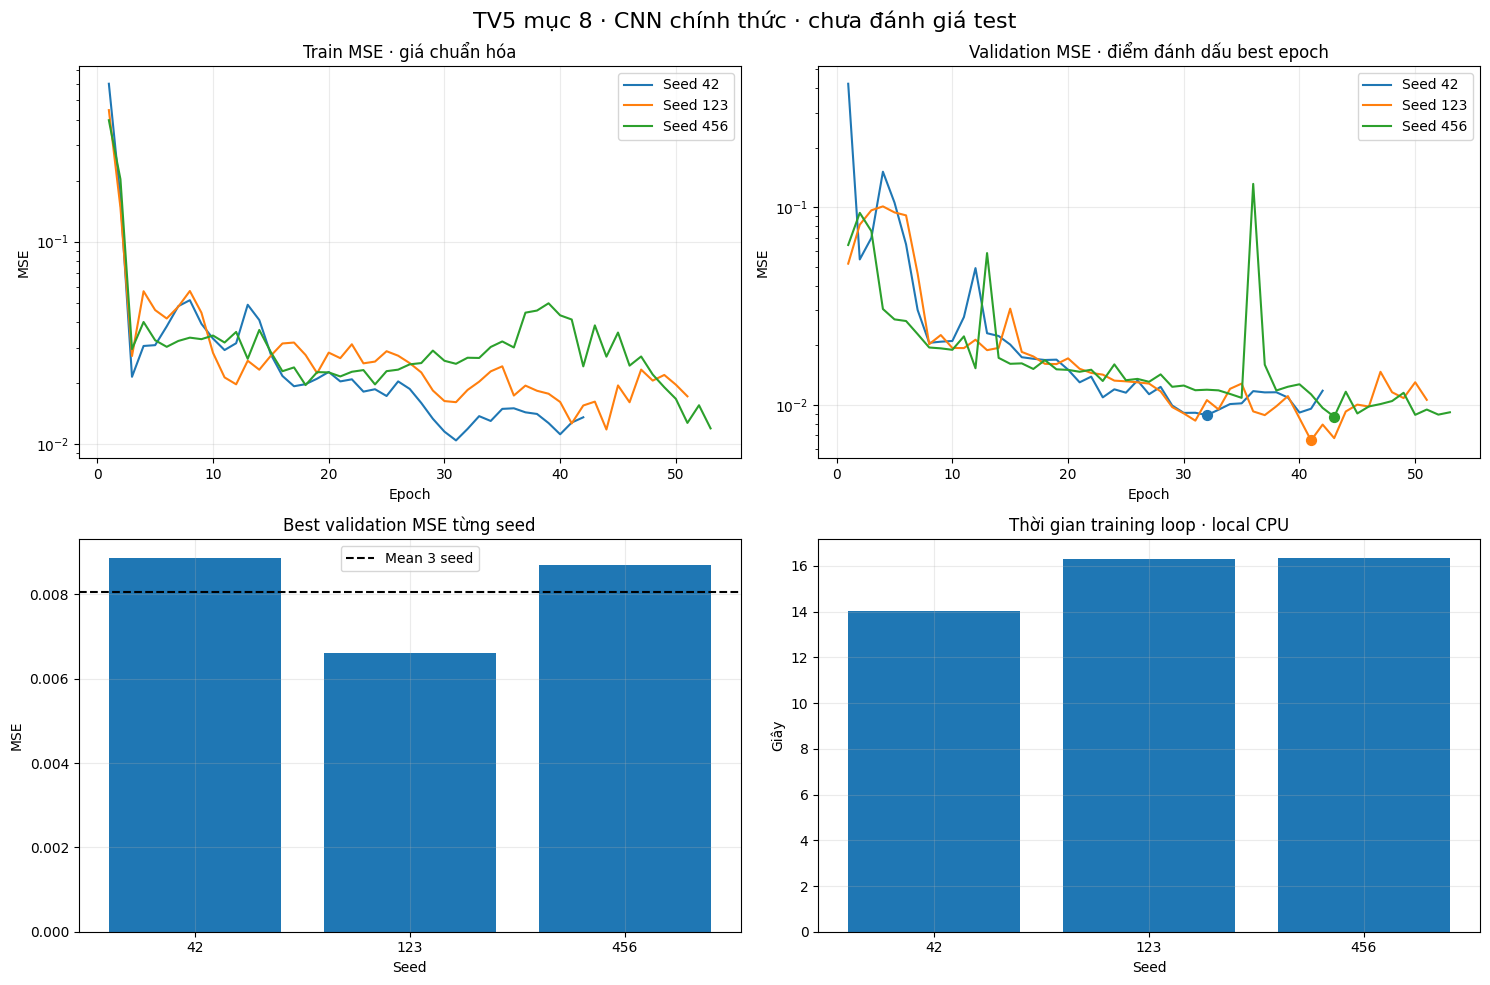

Semantic fingerprint e78dd9f83140e083d8888005fee93e7667b77404beb9d7479941099192da7fa3
Cả ba best checkpoint đã reload khớp True
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item8_20261126T044554616259Z\summary.json


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
official_root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / 'rule.md').is_file())
official_path = sorted((official_root / 'logs/audit').glob('tv5_item8_*/summary.json'))[-1]
official = json.loads(official_path.read_text(encoding='utf-8'))
assert official['passed'] and not official['test_performance_evaluated']
assert official['seeds'] == [42,123,456] and official['total_epochs'] <= 300
table8 = pd.DataFrame(official['results'])
display(table8.drop(columns=['run_id','checkpoint_path']))
display(pd.DataFrame([{k:official[k] for k in ('validation_mse_mean','validation_mse_std',
    'std_ddof','total_epochs','epoch_cap','parameters','dtype','device','torch_threads')}]))
display(pd.DataFrame([official['timing']]))
fig,axes = plt.subplots(2,2,figsize=(15,10))
for row in official['results']:
    history8 = pd.read_csv(official_path.parent / ('history_seed' + str(row['seed']) + '.csv'))
    axes[0,0].plot(history8.epoch,history8.train_loss,label='Seed '+str(row['seed']))
    axes[0,1].plot(history8.epoch,history8.val_loss,label='Seed '+str(row['seed']))
    axes[0,1].scatter([row['best_epoch']],[row['best_val_loss']],s=50)
axes[0,0].set(title='Train MSE · giá chuẩn hóa',xlabel='Epoch',ylabel='MSE',yscale='log')
axes[0,1].set(title='Validation MSE · điểm đánh dấu best epoch',xlabel='Epoch',ylabel='MSE',yscale='log')
axes[0,0].legend(); axes[0,1].legend()
axes[1,0].bar(table8.seed.astype(str),table8.best_val_loss)
axes[1,0].axhline(official['validation_mse_mean'],linestyle='--',color='black',label='Mean 3 seed')
axes[1,0].set(title='Best validation MSE từng seed',xlabel='Seed',ylabel='MSE')
axes[1,0].legend()
axes[1,1].bar(table8.seed.astype(str),table8.training_seconds)
axes[1,1].set(title='Thời gian training loop · local CPU',xlabel='Seed',ylabel='Giây')
for ax in axes.flat: ax.grid(alpha=.25)
fig.suptitle('TV5 mục 8 · CNN chính thức · chưa đánh giá test',fontsize=16)
fig.tight_layout()
fig.savefig(official_path.parent / 'official_overview.png',dpi=150)
display(fig); plt.close(fig)
print('Semantic fingerprint',official['semantic_sha256'])
print('Cả ba best checkpoint đã reload khớp',table8.reload_predictions_exact.all())
print('Bằng chứng',official_path)

## 9. So sánh CNN / LSTM / persistence trên validation — USD

        Cùng 250 sample ID/ngày target năm 2023, cùng input30/scaler/dataset. Giữ ba seed42/123/456 của mỗi mạng, không chọn seed thắng. Dùng best validation checkpoint đã có, inverse bằng scaler train đã lưu và persistence lấy giá USD cuối input. MAE/RMSE dùng module evaluation chung, không làm tròn trước tính metric.

        Đây là so sánh validation đã dùng chọn checkpoint, chưa phải kết luận trên test2024–2025; đánh giá test cuối thuộc flow TV6. LSTM đã chọn lookback từ10/30/60, CNN chỉ một cấu hình, ngân sách tìm kiếm khác nhau. Thời gian train lịch sử chỉ mô tả; timing inference đo local cùng một thread/20 lượt, chưa phải benchmark kernel thuần. Lệnh tái lập `python scripts/compare_tv5_validation.py`.

,method,seed,sample_count,mae_usd,rmse_usd,inference_median_seconds,epochs,historical_training_seconds,parameters
0,persistence,NaN,250,1.636779,2.120593,0.001543,NaN,NaN,0
1,CNN,42.0,250,3.456691,4.573323,0.007192,42.0,14.027544,17057
2,CNN,123.0,250,3.024384,3.947099,0.008874,51.0,16.309433,17057
3,CNN,456.0,250,3.617029,4.531784,0.014681,53.0,16.346363,17057
4,LSTM,42.0,250,1.908008,2.410920,0.029132,100.0,117.651981,4513
5,LSTM,123.0,250,2.078204,2.567211,0.027728,100.0,158.453443,4513
6,LSTM,456.0,250,2.762050,3.275205,0.015622,85.0,250.127244,4513


,method,seeds,mae_usd_mean,mae_usd_std,rmse_usd_mean,rmse_usd_std
0,CNN,3,3.366034,0.306547,4.350735,0.350176
1,LSTM,3,2.249421,0.452032,2.751112,0.460556


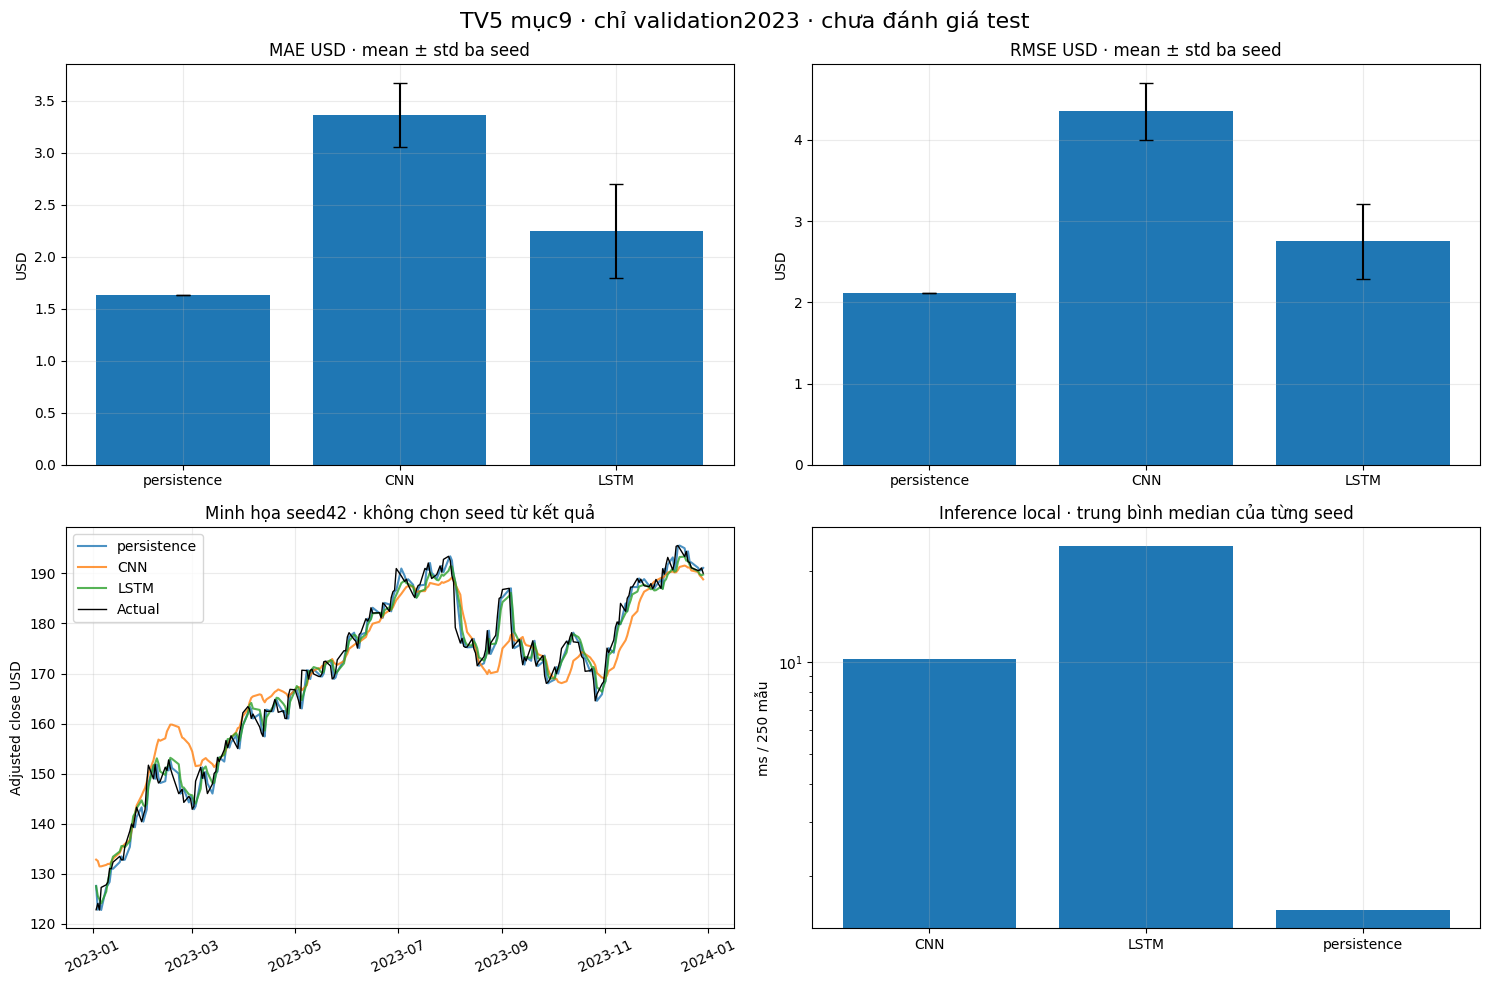

Giới hạn ['Validation used for checkpoint selection; not final test evidence', 'LSTM lookback selected from 10/30/60; CNN fixed Option A, unequal search budgets', 'Historical training timings from different runs are descriptive, not controlled speed benchmarks', 'Inference timing includes DataLoader for networks; persistence includes raw array construction']
Cùng tập mẫu 088ebaeed00ee91117a8a7c84dc915bb8d25af788c9e9885d27ab22c181be31b
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item9_20261126T045347179803Z\summary.json


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
compare_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
compare_path=sorted((compare_root/'logs/audit').glob('tv5_item9_*/summary.json'))[-1]
comparison=json.loads(compare_path.read_text(encoding='utf-8'))
assert comparison['passed'] and comparison['samples']==250 and not comparison['test_performance_evaluated']
metrics9=pd.read_csv(compare_path.parent/'metrics.csv')
predictions9=pd.read_csv(compare_path.parent/'predictions_usd.csv')
aggregates9=pd.DataFrame(comparison['aggregates'])
display(metrics9)
display(aggregates9)
base9=metrics9[metrics9.method=='persistence'].iloc[0]
fig,axes=plt.subplots(2,2,figsize=(15,10))
for ax,metric in zip(axes[0],['mae','rmse']):
    names=['persistence']+aggregates9.method.tolist()
    means=[base9[metric+'_usd']]+aggregates9[metric+'_usd_mean'].tolist()
    stds=[0]+aggregates9[metric+'_usd_std'].tolist()
    ax.bar(names,means,yerr=stds,capsize=5)
    ax.set(title=metric.upper()+' USD · mean ± std ba seed',ylabel='USD')
chosen9=predictions9[(predictions9.seed==42)|(predictions9.method=='persistence')]
for method,part in chosen9.groupby('method',sort=False):
    axes[1,0].plot(pd.to_datetime(part.target_date),part.predicted_usd,label=method,alpha=.8)
actual9=chosen9[chosen9.method=='persistence']
axes[1,0].plot(pd.to_datetime(actual9.target_date),actual9.actual_usd,label='Actual',color='black',linewidth=1)
axes[1,0].set(title='Minh họa seed42 · không chọn seed từ kết quả',ylabel='Adjusted close USD')
axes[1,0].legend(); axes[1,0].tick_params(axis='x',rotation=25)
timing9=metrics9.groupby('method').inference_median_seconds.mean()
axes[1,1].bar(timing9.index,timing9.values*1000)
axes[1,1].set(title='Inference local · trung bình median của từng seed',ylabel='ms / 250 mẫu',yscale='log')
for ax in axes.flat: ax.grid(alpha=.25)
fig.suptitle('TV5 mục9 · chỉ validation2023 · chưa đánh giá test',fontsize=16)
fig.tight_layout();fig.savefig(compare_path.parent/'comparison_overview.png',dpi=150)
display(fig);plt.close(fig)
print('Giới hạn',comparison['limitations'])
print('Cùng tập mẫu',comparison['ordered_keys_sha256'])
print('Bằng chứng',compare_path)

## Bổ sung monitoring chất lượng sau train

        Phân tích lại predictions validation2023 đã đóng băng, không train lại hoặc tuning. Signed error = predicted − actual, dương là dự báo cao. Theo dõi cả ba seed của mỗi mạng và persistence riêng. MAE trượt20 phiên dùng đúng20 mẫu kết thúc tại ngày đang xét; 19 phiên đầu không đủ cửa sổ nên để trống. MAE theo tháng trung bình metric mỗi seed, không tạo ensemble.

        P95/max absolute error và tỷ trọng squared error của5 phiên lớn nhất mô tả tail errors; không coi các seed là mẫu độc lập hoặc suy nguyên nhân chỉ từ biểu đồ. Peak RAM lịch sử chưa đo, không thể tái dựng từ loss log. Chưa có monitoring production/drift hoặc live TensorBoard CNN. CLI tái lập `python scripts/build_tv5_monitoring.py`.

,method,seed,sample_count,mae_usd,rmse_usd,bias_usd,p95_abs_error_usd,max_abs_error_usd,overprediction_fraction,top5_squared_error_share
0,persistence,NaN,250,1.636779,2.120593,-0.250048,4.164545,9.038406,0.436,0.215116
1,CNN,42.0,250,3.456691,4.573323,0.237177,9.919492,13.424248,0.496,0.153054
2,CNN,123.0,250,3.024384,3.947099,-0.284768,8.371864,11.713034,0.432,0.145681
3,CNN,456.0,250,3.617029,4.531784,0.170905,9.360540,11.673664,0.496,0.124078
4,LSTM,42.0,250,1.908008,2.410920,-0.044615,4.446728,9.134057,0.484,0.183208
5,LSTM,123.0,250,2.078204,2.567211,-0.209213,4.931388,8.416412,0.444,0.161404
6,LSTM,456.0,250,2.762050,3.275205,-0.910069,6.052054,7.660026,0.376,0.101137


,method,seed,sample_id,target_date,actual_usd,predicted_usd,error_usd,abs_error_usd,squared_error_usd
0,persistence,NaN,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-08-04,179.183136,188.221542,9.038406,9.038406,81.692790
1,persistence,NaN,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-05-05,170.656967,163.007492,-7.649475,7.649475,58.514469
10,CNN,42.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-08-30,185.005310,171.581062,-13.424248,13.424248,180.210443
11,CNN,42.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-02-21,145.988007,159.287597,13.299591,13.299591,176.879110
20,CNN,123.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-08-30,185.005310,173.292276,-11.713034,11.713034,137.195173
21,CNN,123.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-02-24,144.247726,154.965207,10.717480,10.717480,114.864385
30,CNN,456.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-02-24,144.247726,155.921391,11.673664,11.673664,136.274434
31,CNN,456.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-02-21,145.988007,157.629970,11.641963,11.641963,135.535302
40,LSTM,42.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-08-04,179.183136,188.317193,9.134057,9.134057,83.431004
41,LSTM,42.0,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2023-09-07,175.057495,182.976366,7.918871,7.918871,62.708524


,telemetry,status
0,training_loss,recorded per epoch
1,validation_loss,recorded per epoch
2,nonfinite_checks,trainer guards and smoke gradient probes
3,checkpoint_reload,six models checked in item9
4,cnn_wall_seconds,107.627914
5,cnn_cpu_seconds,93.484375
6,inference_timing,"item9 median20 local, includes input/loader ov..."
7,historical_peak_ram,not recorded; cannot reconstruct retrospectively
8,gpu_telemetry,"not applicable, CPU experiment"
9,production_drift,not implemented; no deployed model


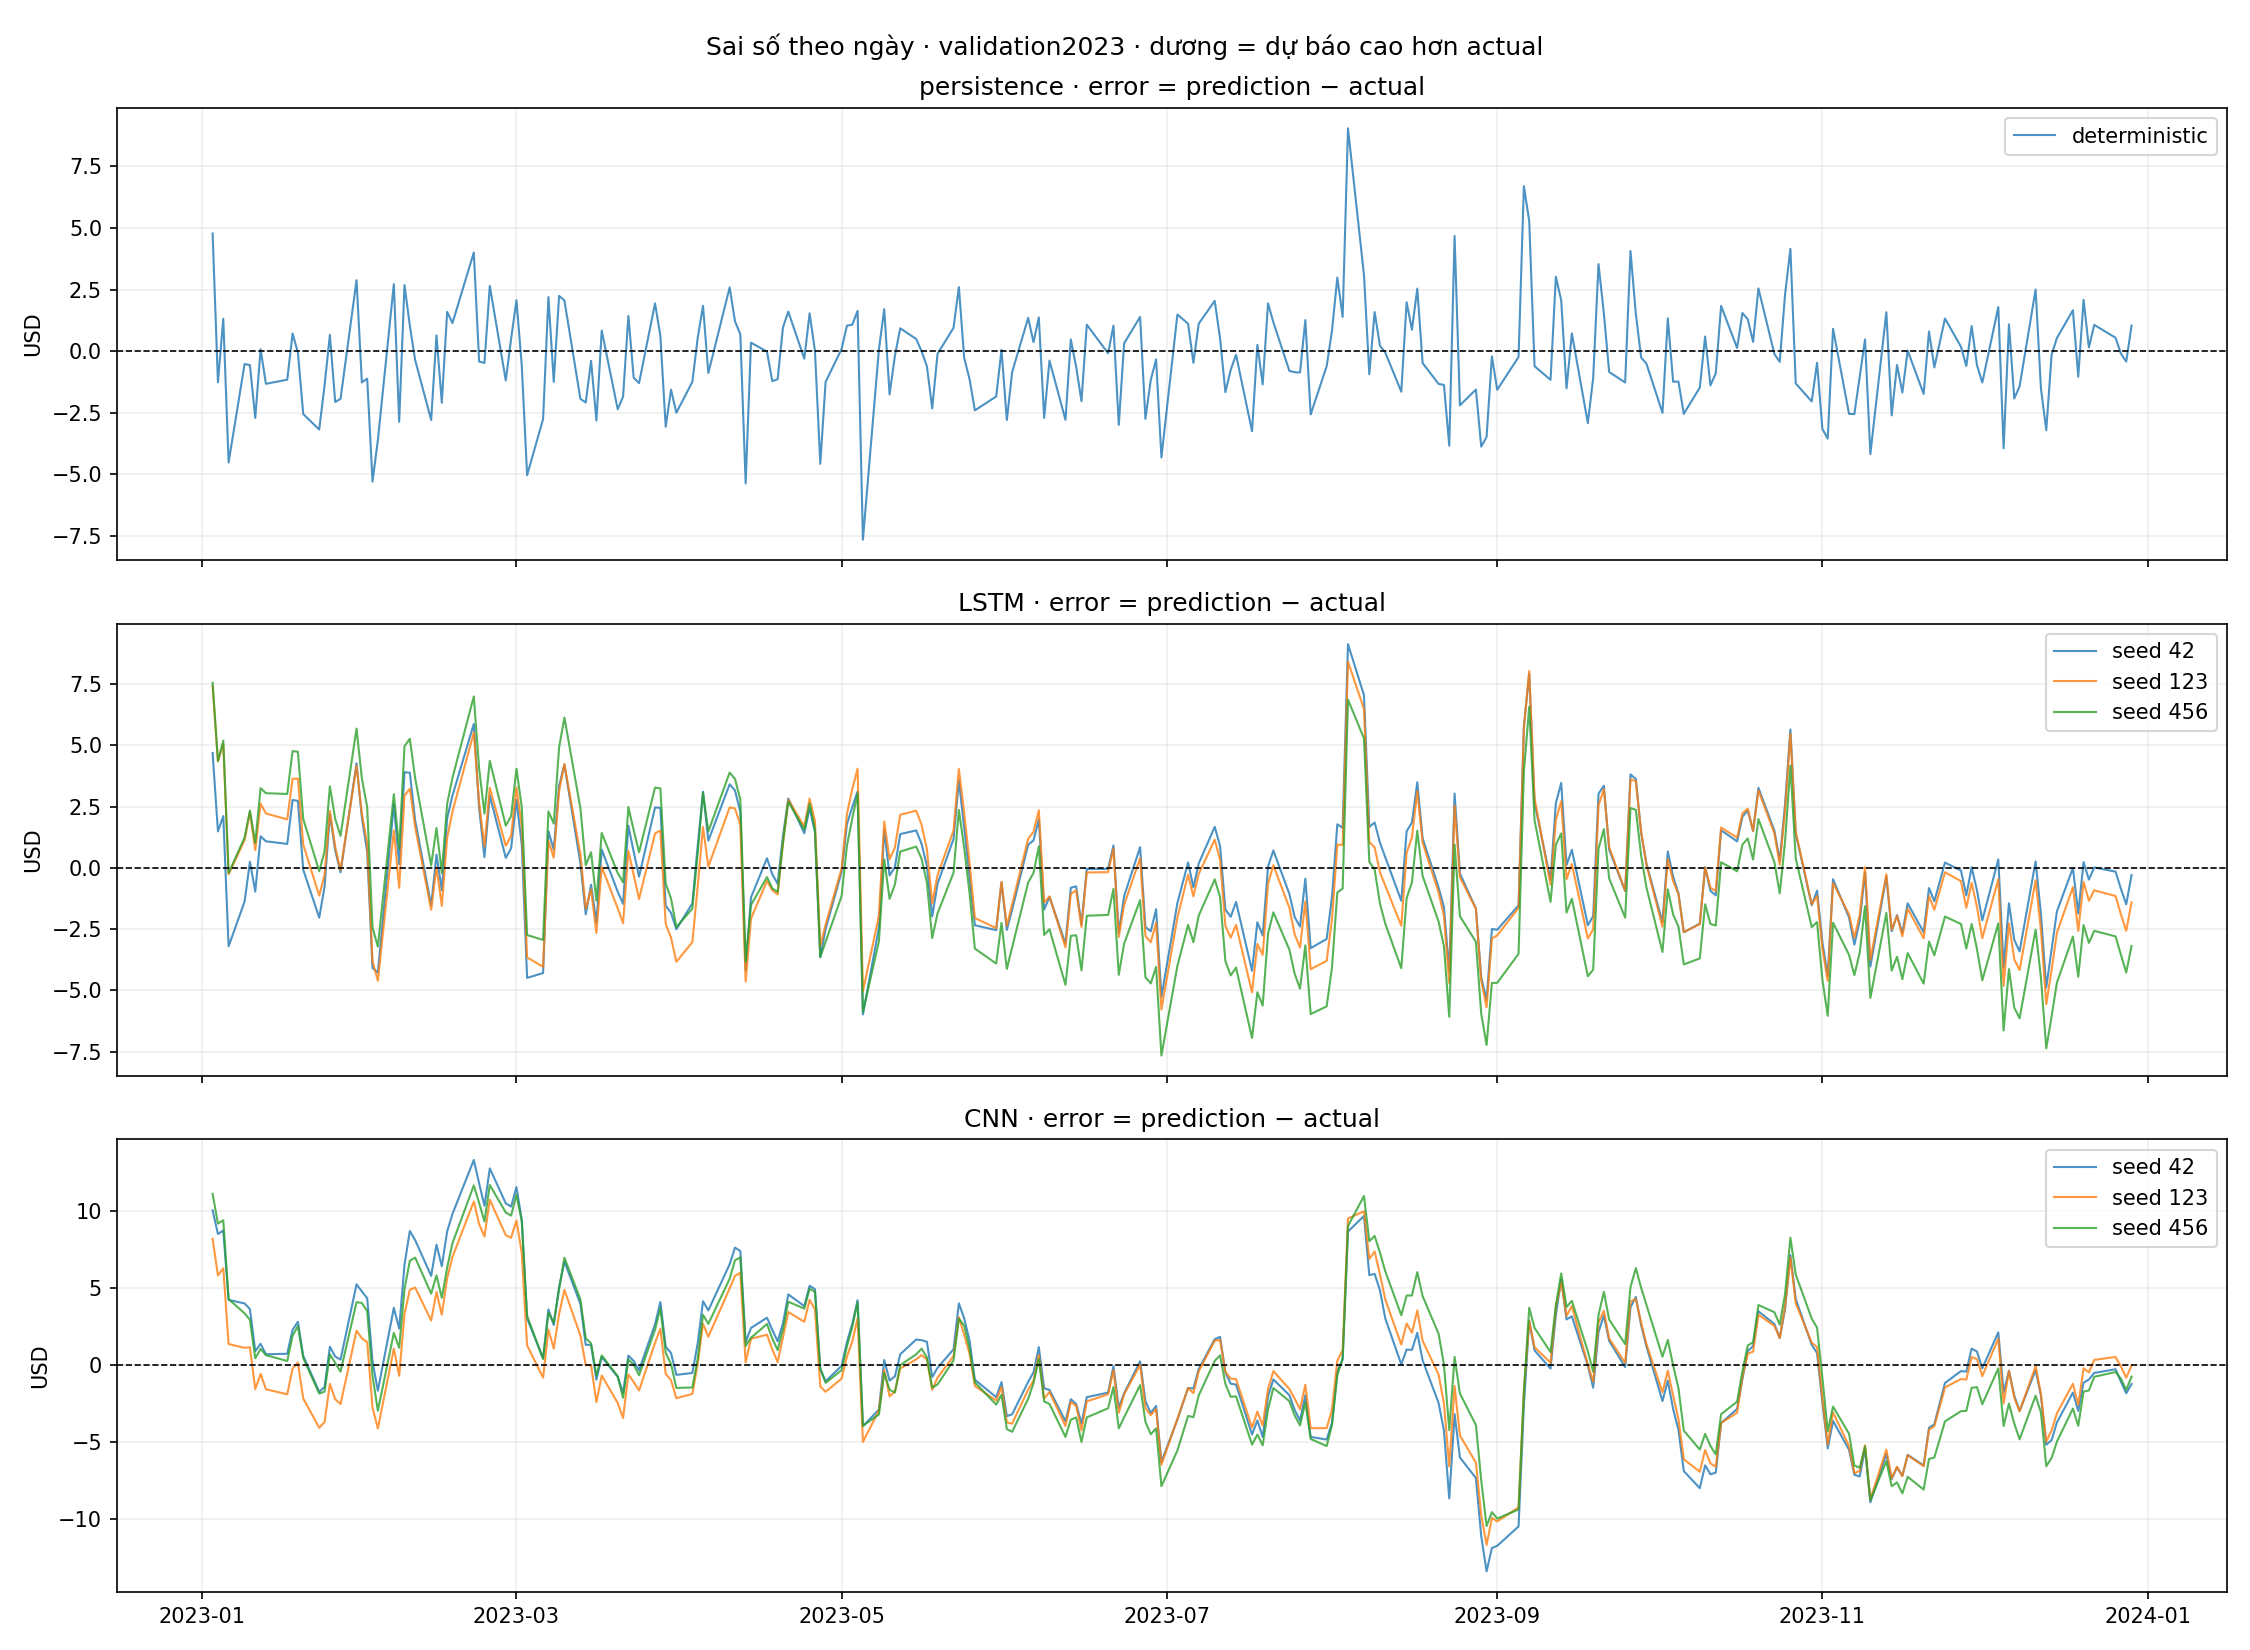

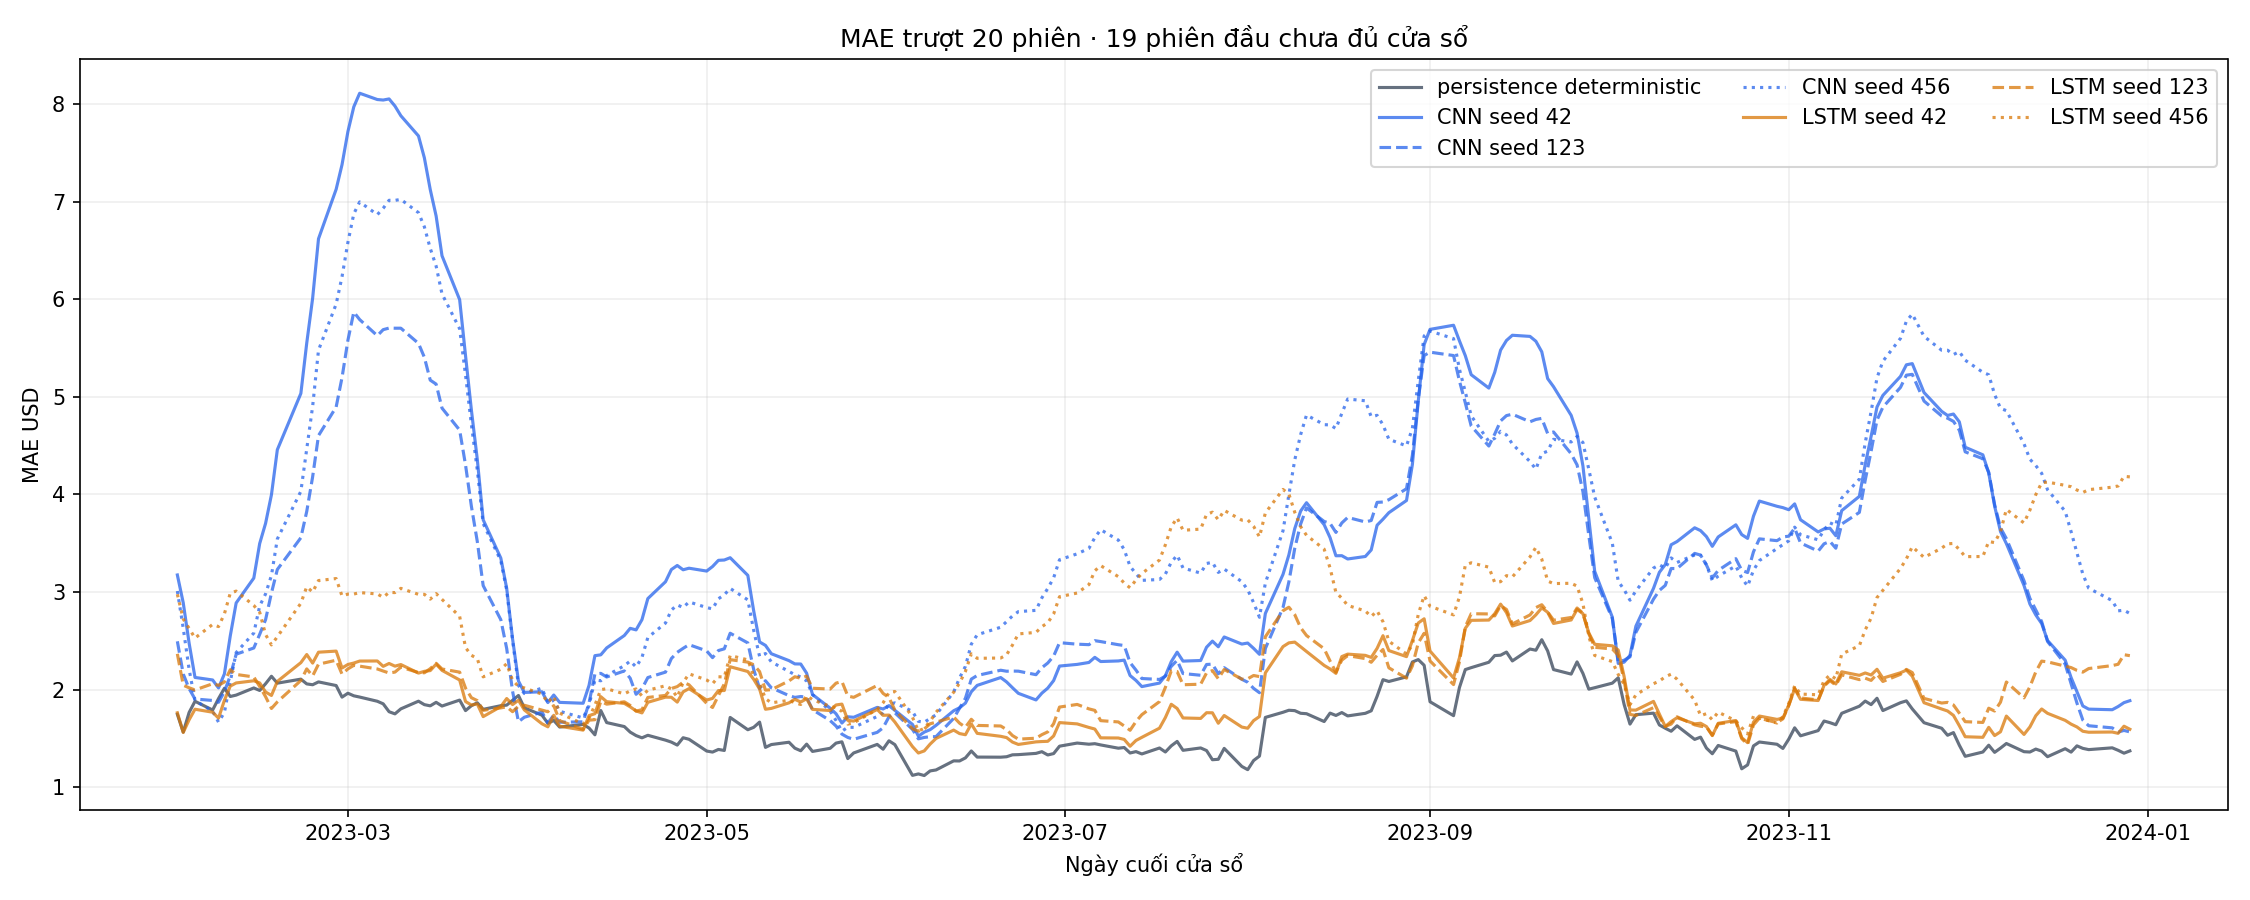

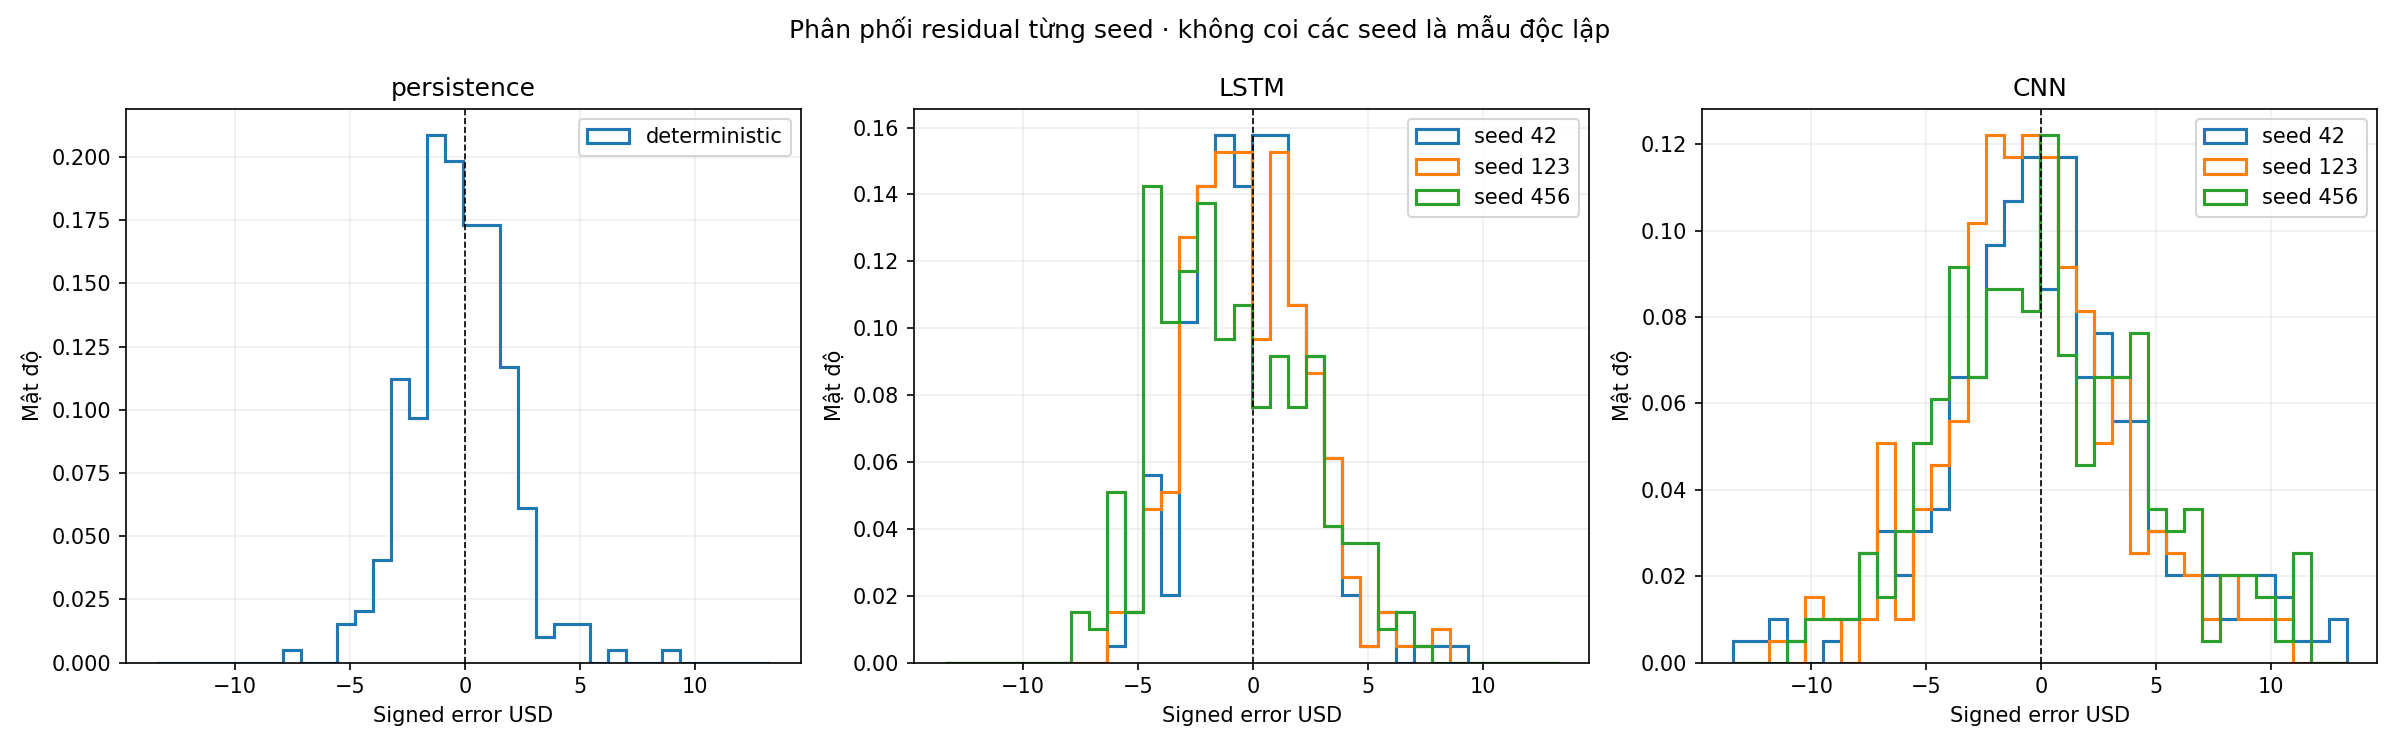

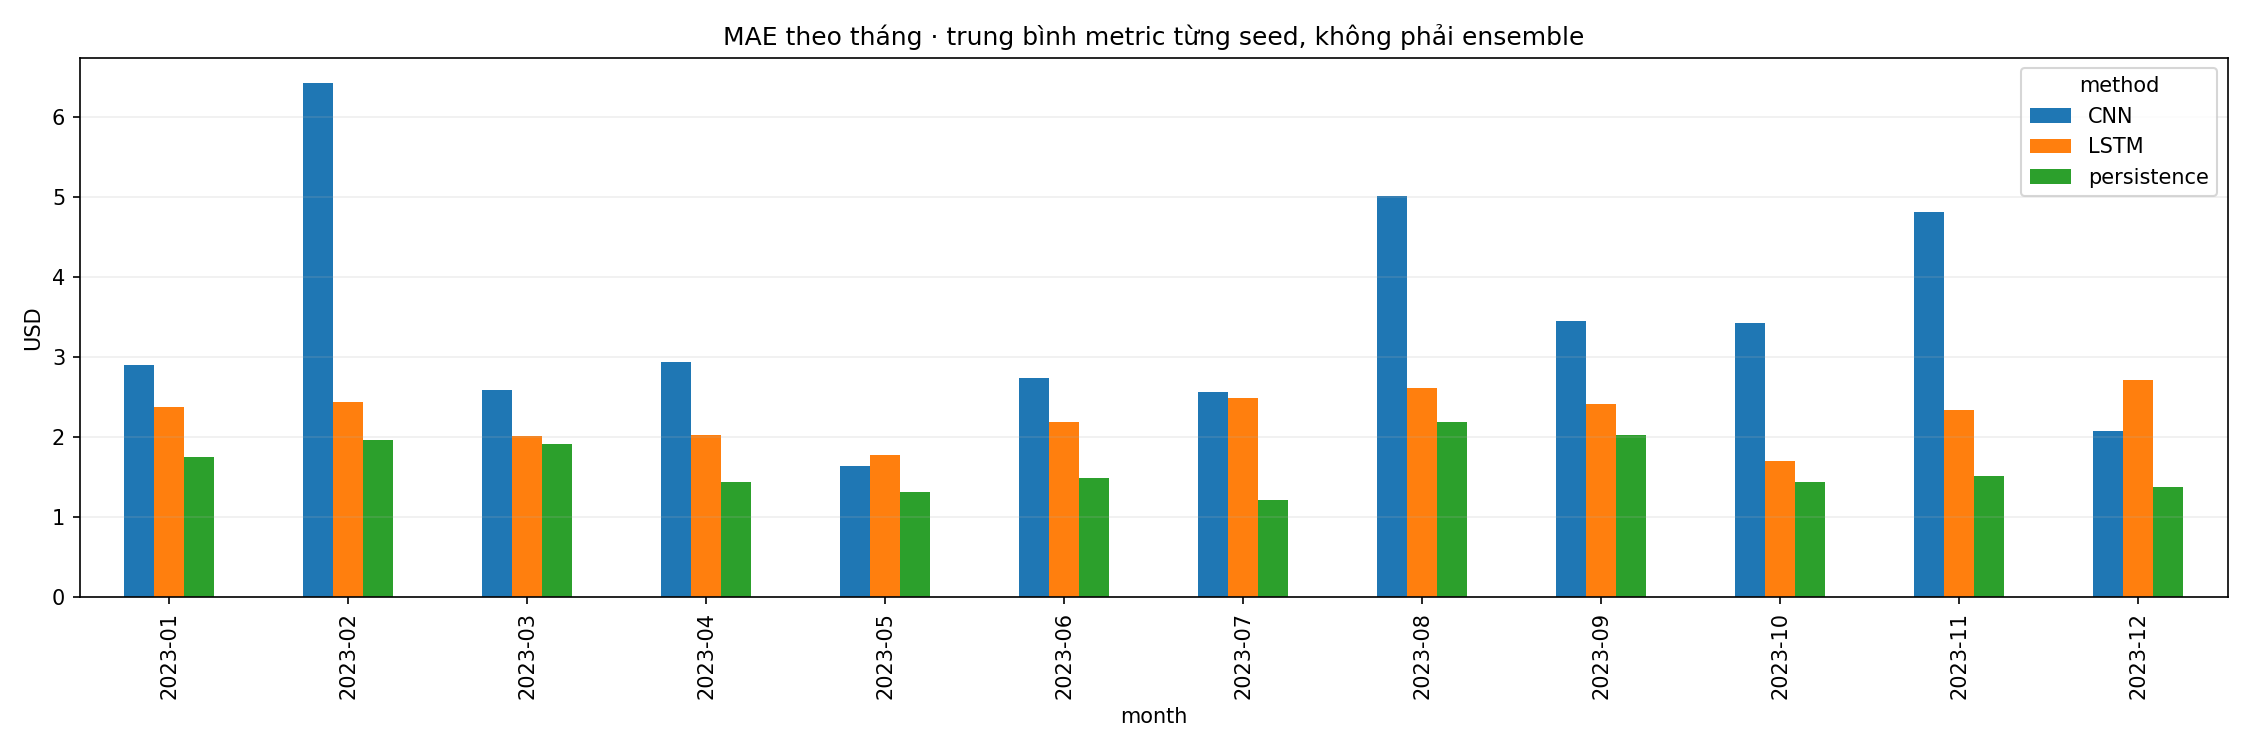

Top10 từng run và bảng tháng/rolling đầy đủ D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_monitoring_20261126T091236219563Z
Giới hạn ['Validation selected checkpoints; descriptive analysis only', 'No causal claim about CNN errors or proof of absence of overfitting', 'No historical peak RAM, live TensorBoard CNN, alerting or production drift telemetry']
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_monitoring_20261126T091236219563Z\summary.json


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
monitor_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
monitor_path=sorted((monitor_root/'logs/audit').glob('tv5_monitoring_*/summary.json'))[-1]
monitor=json.loads(monitor_path.read_text(encoding='utf-8'))
assert monitor['passed'] and not monitor['trained_again'] and not monitor['test_performance_evaluated']
monitor_stats=pd.read_csv(monitor_path.parent/'summary.csv')
monitor_top=pd.read_csv(monitor_path.parent/'largest.csv')
display(monitor_stats)
display(monitor_top.groupby(['method','seed'],dropna=False,sort=False).head(2))
display(pd.DataFrame([{'telemetry':k,'status':v} for k,v in monitor['resource_inventory'].items()]))
for name in ['01_errors_by_date.png','02_rolling_mae.png','03_error_distributions.png','04_monthly_mae.png']:
    display(Image(filename=str(monitor_path.parent/name)))
print('Top10 từng run và bảng tháng/rolling đầy đủ',monitor_path.parent)
print('Giới hạn',monitor['limitations'])
print('Bằng chứng',monitor_path)

## 10. Audit cuối, tái lập và bàn giao TV5

        Đủ source/config/tests/notebook và artifacts local cho CNN một bước. Gói gồm ba best CNN research, ba LSTM đối ứng, best smoke diagnostic và dependencies TV1/TV2/log TV4. Payload hash từng file, ZIP checksum riêng. Tái lập dùng source tách riêng và venv sạch đã có, chạy tests rồi forward/reload/metrics/monitoring; không train lại AAPL.

        Hướng dẫn docs/TV5_Setup_and_Handoff.md, audit reports/audits/TV5_Final_Handoff.md. Đây là nghiệm thu local, không chứng nhận máy người nhận/fresh install/test2024–2025/API. Peak RAM lịch sử và monitoring production chưa có. Dữ liệu/weights/ZIP không đưa vào Git hoặc tự upload. Kết quả validation vẫn persistence tốt hơn LSTM/CNN; không ép model thắng baseline.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
handoff_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
precheck_path=handoff_root/'logs/audit/tv5_item10_precheck.json'
precheck=json.loads(precheck_path.read_text(encoding='utf-8'))
assert precheck['passed'] and precheck['tests']==162 and precheck['relocated_metrics_match']
assert not precheck['recipient_machine_verified'] and not precheck['test_performance_evaluated']
display(pd.DataFrame([precheck]))
display(pd.DataFrame([{'item':i,'status':'Hoàn thành phạm vi local'} for i in range(1,11)]))
print('Bằng chứng kiểm source tách riêng',precheck_path)
pointer_path=handoff_root/'logs/audit/tv5_item10_latest.json'
if pointer_path.is_file():
    print('Gói/receipt ZIP mới nhất',json.loads(pointer_path.read_text(encoding='utf-8')))
else:
    print('Pointer ZIP và checksum được ghi sau bước đóng gói cuối; xem audit/setup.')

,passed,tests,relocated_metrics_match,cnn_research_models,lstm_comparison_models,imports_from_relocated_root,existing_clean_environment_verified,recipient_machine_verified,test_performance_evaluated,aapl_retrained,stage_evidence,payload_files
0,True,162,True,3,3,True,True,False,False,False,D:\learn_DeepLearning\Project_course-work\.ven...,533


,item,status
0,1,Hoàn thành phạm vi local
1,2,Hoàn thành phạm vi local
2,3,Hoàn thành phạm vi local
3,4,Hoàn thành phạm vi local
4,5,Hoàn thành phạm vi local
5,6,Hoàn thành phạm vi local
6,7,Hoàn thành phạm vi local
7,8,Hoàn thành phạm vi local
8,9,Hoàn thành phạm vi local
9,10,Hoàn thành phạm vi local


Bằng chứng kiểm source tách riêng D:\learn_DeepLearning\Project_course-work\logs\audit\tv5_item10_precheck.json
Pointer ZIP và checksum được ghi sau bước đóng gói cuối; xem audit/setup.
